# 02 — Question answering

**Objective.** Answer each question from document evidence with a cited page list under the four frozen baseline conditions, then prepare and (only when explicitly enabled) execute Experiment E1's controlled 512-versus-768 oracle-image comparison.

| | Retrieved pages (BM25 top 5) | Oracle pages (evidence, padded to 5) |
|---|---|---|
| **Extracted text** (native + OCR) | **A** | **C** |
| **Rendered page images** | **B** | **D** |

| | |
|---|---|
| **Input** | `questions.parquet`, `pages.parquet`, baseline `render_manifest.csv`, E1 `render_manifest_e1.csv` and page images (00); `rankings.parquet` (01); frozen baseline runs; tracked `experiments/specs/e1_image_resolution_v1.json` |
| **Output** | Baseline replay in `data/processed/mmlongbench_doc/predictions/`; regenerable E1 design, feasibility and cost files in `data/processed/mmlongbench_doc/e1/`; immutable paid E1 artifacts only in a unique `experiments/runs/e1/` directory |
| **Next** | `03_evaluation.ipynb` scores saved responses without making API calls |

**Baseline run modes** (`VISUALDOC_QA_MODE`): `replay` (default, no API), `smoke`, `pilot`, or `full`. Frozen replay and its cache behavior are unchanged.

**E1 run modes** (`VISUALDOC_E1_MODE`):

| mode | API calls | scientific use |
|---|---:|---|
| `offline` (default) | 0 | rebuild requests, verify images, population, ordering, cache isolation and costs |
| `smoke` | 2 | one matched 512/768 technical pair; token-accounting and interface gate only |
| `pilot` | 2 smoke + 16 pilot | technical feasibility on eight selected questions; no improvement claim |
| `full` | 2 smoke + 74 main + 37 repeated controls | primary paired comparison plus an independent 512-px control replicate |

Every paid E1 run gets a unique immutable run ID. The main requests are adjacent 512/768 pairs by question, with seeded question order and seeded within-pair order. E1 cache keys are namespaced by run and replicate, so a new replicate cannot receive an earlier response.

## Method

**Only the evidence changes between conditions.** Held constant: questions, reference answers, the page list and its order, the `[Page N]` labels (1-based physical pages, so citations compare directly with `evidence_pages`), the model snapshot, temperature 0, `max_completion_tokens` = 400, JSON output mode, the answer parser and (in 03) the scorer.

**Oracle pages.** For evidence pages $E$ and BM25 ranking $R$: all of $E$, padded with the best-ranked non-evidence pages up to $k = 5$, in BM25 rank order. Padding keeps $k$ constant: an evidence-only context would change two things at once (evidence present *and* distractors gone). When BM25 already had all the evidence, the oracle context equals the retrieved one, which gives a built-in noise check. When $|E| > 5$, all evidence pages are supplied (10 and 13 pages for two counting questions).

**Answer contract.** The model returns JSON `{"answer": …, "cited_pages": […]}`, with the exact string `"Not answerable"` to abstain. The reference `answer_format` is never sent: format `None` means "unanswerable", so it would leak the label. Structured output replaces the official GPT-4o answer-extraction stage, so scores are local diagnostics, not leaderboard numbers.

**What differs besides the representation** (stated, not hidden):
1. The image system prompt replaces "page excerpts" with "page images" in 5 of 10 lines.
2. Text is truncated at 3,500 characters per page; images are never truncated.
3. **Resolution is set by cost.** gpt-4o-mini counts each 512-px image tile as about 5,667 input tokens:
   $$\text{tokens}(\text{image}) = 2{,}833 + 5{,}667 \cdot \left\lceil w'/512 \right\rceil \left\lceil h'/512 \right\rceil.$$
   At the API's default size (short side 768 px) five pages exceed the 128k context, so pages are rendered into a 512 × 1024 box (2 tiles, ≈ 14k tokens per page, ≈ 60 dpi for a letter page). A smoke test measured that the API does not upscale these images.
4. Oracle image requests that cannot fit the context are **skipped by protocol before any call**, and every comparison with D restricts the other side to the same questions.

**API safety.** Errors are classified from the exception class and API `code` (a credit-exhausted error is an HTTP 429 but must not be retried); only rate limits, timeouts and 5xx are retried, at most 3 times; the first unrecoverable error stops the batch; and **no metric is reported unless every question of a condition received a reply**. Frozen baseline image replies keep their existing request-fingerprint cache behavior. E1 uses a stricter run-and-replicate namespace: only an interrupted execution of the same immutable replicate may reuse a response; a new replicate always makes a new call.

In [1]:
from collections import Counter, deque
from datetime import datetime, timezone
from math import ceil
from pathlib import Path
import base64
import hashlib
import json
import os
import platform
import re
import sys
import tempfile
import time
import uuid

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import tiktoken
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
PDF_DIR = PROJECT_ROOT / "data" / "external" / "mmlongbench_doc" / "documents"
CACHE_DIR = PROJECT_ROOT / "data" / "cache" / "mmlongbench_doc"
FROZEN_TEXT_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "text_run_20261119T220858Z_a351a532"
FROZEN_IMAGE_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "image_run_20261119T232847Z_65ccf1ef"
RUNS_DIR = PROJECT_ROOT / "experiments" / "runs" / "qa"  # new live runs (git-ignored)

try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env")
except ImportError:
    pass  # plain environment variables still work

SETTINGS = {
    "qa_mode": os.getenv("VISUALDOC_QA_MODE", "replay"),
    "e1_mode": os.getenv("VISUALDOC_E1_MODE", "offline"),
    "model_provider": "openai",
    "model_name": os.getenv("VISUALDOC_QA_MODEL", "gpt-4o-mini-2024-07-18"),  # the snapshot that served every frozen reply
    "temperature": 0.0,
    "max_output_tokens": 400,
    "generation_top_k": 5,
    "max_chars_per_page": 3500,
    "text_prompt_version": "mmlb-structured-v1",
    "image_prompt_version": "mmlb-image-v1",
    "seed": 42,
    "pilot_size": 5,
    "image_detail": "high",
    "image_base_tokens": 2833,
    "image_tile_tokens": 5667,
    "context_window_tokens": 128_000,
    "price_usd_per_1m_input_tokens": 0.15,  # assumed list prices for gpt-4o-mini: verify before relying on costs
    "price_usd_per_1m_output_tokens": 0.60,
    "max_estimated_live_cost_usd": 2.50,  # an image batch estimated above this is refused
    "default_tokens_per_minute": 150_000,
    "reuse_cached_responses": True,
    "max_attempts": 3,
    "request_timeout_s": 120,
}
assert SETTINGS["qa_mode"] in {"replay", "smoke", "pilot", "full"}, "VISUALDOC_QA_MODE must be replay, smoke, pilot or full"
assert SETTINGS["e1_mode"] in {"offline", "smoke", "pilot", "full"}, "VISUALDOC_E1_MODE must be offline, smoke, pilot or full"
MODE = SETTINGS["qa_mode"]
E1_MODE = SETTINGS["e1_mode"]
print(f"Baseline mode: {MODE!r}; E1 mode: {E1_MODE!r} ({'no E1 API call' if E1_MODE == 'offline' else 'PAID E1 calls explicitly enabled'}) | model {SETTINGS['model_name']}")

Baseline mode: 'replay'; E1 mode: 'offline' (no E1 API call) | model gpt-4o-mini-2024-07-18


In [2]:
for name in ("questions.parquet", "pages.parquet", "render_manifest.csv", "render_manifest_e1.csv", "rankings.parquet"):
    assert (PROCESSED_DIR / name).is_file(), f"{name} is missing: run 00_document_processing and 01_retrieval first"


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


questions = pd.read_parquet(PROCESSED_DIR / "questions.parquet")
subset = questions[questions["in_subset"]].reset_index(drop=True)
subset = subset.merge(pd.read_parquet(PROCESSED_DIR / "rankings.parquet")[["qid", "ranking"]], on="qid", validate="one_to_one")
# Parquet returns list columns as NumPy arrays: convert to plain Python lists (ints serialise to JSON as numbers).
subset["evidence_sources"] = subset["evidence_sources"].map(list)
for column in ("evidence_pages", "ranking"):
    subset[column] = subset[column].map(lambda values: [int(v) for v in values])

pages = pd.read_parquet(PROCESSED_DIR / "pages.parquet")
page_lookup = pages.set_index(["doc_id", "page"])
manifest = pd.read_csv(PROCESSED_DIR / "render_manifest.csv").set_index(["doc_id", "page"])
e1_manifest = pd.read_csv(PROCESSED_DIR / "render_manifest_e1.csv").set_index(["doc_id", "page"])
RENDER_LABEL = Path(manifest["image_path"].iloc[0]).parts[-3]  # e.g. short512-long1024
frozen_text_settings = json.loads((FROZEN_TEXT_RUN / "settings.json").read_text())
frozen_image_settings = json.loads((FROZEN_IMAGE_RUN / "settings.json").read_text())
E1_RENDER_LABEL = Path(e1_manifest["image_path"].iloc[0]).parts[-3]
assert set(manifest.index) == set(e1_manifest.index) == set(page_lookup.index)
print(f"{len(subset)} questions, {len(pages)} page records, {len(manifest)} baseline images ({RENDER_LABEL}), "
      f"and {len(e1_manifest)} E1 images ({E1_RENDER_LABEL})")

57 questions, 195 page records, 195 baseline images (short512-long1024), and 195 E1 images (short768-long1536)


## 1. Page lists for the four conditions

First the oracle rule on hand-made cases, then the page lists for every question. The lists must equal, element by element and in order, the `supplied_pages` recorded in the frozen runs: those are the pages the model actually received.

In [3]:
gen_k = SETTINGS["generation_top_k"]


def oracle_pages(evidence, ranking, k):
    # All evidence pages, padded with the best-ranked non-evidence pages up to k, in ranking order.
    evidence = set(evidence)
    padding = [page for page in ranking if page not in evidence][: max(0, k - len(evidence))]
    chosen = evidence | set(padding)
    return [page for page in ranking if page in chosen]


assert oracle_pages([3, 7], [7, 1, 2, 3, 4], 3) == [7, 1, 3]  # page 3 replaces page 2, the lowest-ranked distractor
assert oracle_pages([7, 1], [7, 1, 2, 3, 4], 3) == [7, 1, 2]  # BM25 already had all evidence: unchanged top 3
assert oracle_pages([1, 2, 3, 4], [4, 9, 3, 2, 1], 2) == [4, 3, 2, 1]  # |E| > k: all evidence, no padding

has_evidence = subset["answerable"] & subset["n_evidence_pages"].gt(0) & ~subset["evidence_pages"].map(lambda e: 0 in e)
subset["retrieved_pages"] = subset["ranking"].map(lambda r: r[:gen_k])
subset["oracle_pages"] = [oracle_pages(e, r, gen_k) if ok else None for e, r, ok in zip(subset["evidence_pages"], subset["ranking"], has_evidence)]
recall = [len(set(e) & set(r)) / len(set(e)) if ok else np.nan for e, r, ok in zip(subset["evidence_pages"], subset["retrieved_pages"], has_evidence)]
subset["retrieval_group"] = np.select([~subset["answerable"], np.array(recall) == 1, np.array(recall) > 0],
                                      ["unanswerable", f"all evidence in top {gen_k}", f"some evidence in top {gen_k}"], f"no evidence in top {gen_k}")
VISUAL_SOURCES = {"Chart", "Figure"}
subset["evidence_group"] = np.where(~subset["answerable"], "unanswerable",
                                    np.where(subset["evidence_sources"].map(lambda s: bool(VISUAL_SOURCES & set(s))), "chart or figure", "text, layout or table only"))

CONDITIONS = {
    "A": {"label": "A. text, retrieved", "representation": "text", "pages": "retrieved_pages", "frozen": FROZEN_TEXT_RUN / "predictions.jsonl"},
    "B": {"label": "B. images, retrieved", "representation": "image", "pages": "retrieved_pages", "frozen": FROZEN_IMAGE_RUN / "predictions_retrieved_images.jsonl"},
    "C": {"label": "C. text, oracle", "representation": "text", "pages": "oracle_pages", "frozen": FROZEN_TEXT_RUN / "oracle_predictions.jsonl"},
    "D": {"label": "D. images, oracle", "representation": "image", "pages": "oracle_pages", "frozen": FROZEN_IMAGE_RUN / "predictions_oracle_images.jsonl"},
}
frozen_records = {name: read_jsonl(spec["frozen"]) for name, spec in CONDITIONS.items()}
pages_by_qid = subset.set_index("qid")
for name, spec in CONDITIONS.items():
    expected_qids = subset.loc[subset[spec["pages"]].notna(), "qid"].tolist()
    assert [r["qid"] for r in frozen_records[name]] == expected_qids, name
    assert all(r["supplied_pages"] == pages_by_qid.loc[r["qid"], spec["pages"]] for r in frozen_records[name]), name

print("Page lists for A, B, C and D equal the frozen supplied pages, in order.")
print("Oracle list sizes:", dict(Counter(subset["oracle_pages"].dropna().map(len))))
display(subset.groupby(["retrieval_group", "evidence_group"]).size().unstack(fill_value=0))
subset.loc[subset["oracle_pages"].notna() & (subset["oracle_pages"] != subset["retrieved_pages"]),
           ["qid", "evidence_pages", "retrieved_pages", "oracle_pages"]].head(6)

Page lists for A, B, C and D equal the frozen supplied pages, in order.
Oracle list sizes: {5: 38, 13: 1, 10: 1}


evidence_group,chart or figure,"text, layout or table only",unanswerable
retrieval_group,,,
all evidence in top 5,20,4,0
no evidence in top 5,4,4,0
some evidence in top 5,8,0,0
unanswerable,0,0,17


,qid,evidence_pages,retrieved_pages,oracle_pages
2,mmlb-0035,"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]","[39, 9, 30, 2, 31]","[31, 11, 22, 16, 27, 13, 15, 21, 23, 24, 25, 26, 38]"
3,mmlb-0036,"[14, 19, 20, 33, 37]","[38, 30, 2, 5, 7]","[19, 33, 14, 20, 37]"
4,mmlb-0037,[33],"[31, 32, 19, 30, 13]","[31, 32, 19, 30, 33]"
6,mmlb-0039,"[6, 7, 8, 11, 18, 23, 24, 25, 28, 30]","[17, 2, 9, 40, 21]","[30, 23, 7, 11, 6, 28, 8, 18, 25, 24]"
14,mmlb-0313,[11],"[25, 27, 9, 10, 26]","[25, 27, 9, 10, 11]"
18,mmlb-0317,"[14, 15]","[12, 14, 46, 26, 44]","[12, 14, 46, 26, 15]"


24 answerable questions have all their evidence in the top 5 (their C/D context equals A/B), 8 have some and 8 have none. For the last group, conditions A and B cannot answer from evidence, whatever the representation.

The **pilot** is a fixed, seeded sample: 4 answerable and 1 unanswerable question, drawn with its own generator.

In [4]:
pilot_rng = np.random.default_rng(SETTINGS["seed"])
pilot_qids = sorted(
    pilot_rng.choice(sorted(subset.loc[subset["answerable"], "qid"]), size=SETTINGS["pilot_size"] - 1, replace=False).tolist()
    + pilot_rng.choice(sorted(subset.loc[~subset["answerable"], "qid"]), size=1, replace=False).tolist()
)
assert pilot_qids == frozen_text_settings["pilot_qids"] == frozen_image_settings["pilot_qids"]
subset[subset["qid"].isin(pilot_qids)][["qid", "doc_id", "answer_format", "evidence_group", "retrieval_group"]]

,qid,doc_id,answer_format,evidence_group,retrieval_group
3,mmlb-0036,earlybird-110722143746-phpapp02_95.pdf,Int,chart or figure,no evidence in top 5
23,mmlb-0355,PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Str,chart or figure,all evidence in top 5
36,mmlb-0731,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95...,List,chart or figure,all evidence in top 5
39,mmlb-0734,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95...,None,unanswerable,unanswerable
41,mmlb-0736,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95...,Int,chart or figure,all evidence in top 5


## 2. Text evidence

Each supplied page becomes a block `[Page N]` followed by its text (native, or OCR below the 30-word threshold), truncated at 3,500 characters. A page without text is marked instead of disappearing.

In [5]:
TEXT_SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page excerpts provided.
Each excerpt starts with a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the excerpts do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose excerpts support the answer ([] if "Not answerable").

Do not use knowledge outside the excerpts. Do not guess."""

page_text = page_lookup["text"].to_dict()


def build_user_message(question, doc_id, supplied_pages, max_chars=SETTINGS["max_chars_per_page"]):
    blocks = []
    for page in supplied_pages:
        text = page_text[(doc_id, page)].strip()
        if len(text) > max_chars:
            text = text[:max_chars] + " [...truncated]"
        blocks.append(f"[Page {page}]\n{text or '(no extractable text on this page)'}")
    return f"Question: {question}\n\nPage excerpts:\n\n" + "\n\n".join(blocks)


TEXT_PROMPT_HASH = hashlib.sha256((SETTINGS["text_prompt_version"] + TEXT_SYSTEM_PROMPT).encode()).hexdigest()[:12]
assert TEXT_SYSTEM_PROMPT == frozen_text_settings["system_prompt"] and TEXT_PROMPT_HASH == frozen_text_settings["prompt_hash"]

example = subset[subset["answerable"] & (subset["n_evidence_pages"] == 1)].iloc[0]
lengths = [len(build_user_message(r.question, r.doc_id, r.retrieved_pages)) for r in subset.itertuples()]
print(f"Text prompt identical to the frozen run (hash {TEXT_PROMPT_HASH}). User-message length: median {np.median(lengths):,.0f}, max {max(lengths):,} chars.")
print("-" * 80)
print(build_user_message(example["question"], example["doc_id"], example["retrieved_pages"])[:700], "\n[... preview truncated ...]")

Text prompt identical to the frozen run (hash f60729bf0b66). User-message length: median 9,092, max 17,734 chars.
--------------------------------------------------------------------------------
Question: How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?

Page excerpts:

[Page 6]
At the same time,e    real performanceGg        shows
European VCa   | drivingee   the best exito multiplese
globally


  Exits over $ 100M
 2005 - Q1/2011





                                                             7.2

                                                                           Median Multiple
                                                                                             of Cash Invested                        45
                                                                                    
[... preview truncated ...]


## 3. Image evidence

The same request with the page text replaced by pixels: the question, then for each page a `[Page N]` tag followed by that page's PNG (Base64 data URL, `detail: high`). No extracted text, no annotation field and no reference answer is sent. Saved records replace each image by its SHA-256, so a log line is a few KB instead of ~1 MB, and the **request fingerprint** (a hash of everything that can change the reply) identifies a request for the response cache.

In [6]:
IMAGE_SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page images provided.
Each page image is preceded by a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the page images do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose images support the answer ([] if "Not answerable").

Do not use knowledge outside the page images. Do not guess."""

IMAGE_PROMPT_HASH = hashlib.sha256((SETTINGS["image_prompt_version"] + IMAGE_SYSTEM_PROMPT).encode()).hexdigest()[:12]
assert IMAGE_PROMPT_HASH == frozen_image_settings["image_prompt_hash"]

# Only the words that describe the evidence differ: undoing them gives back the text prompt exactly.
undone = IMAGE_SYSTEM_PROMPT
for image_words, text_words in [("page images provided", "page excerpts provided"), ("Each page image is preceded by a tag", "Each excerpt starts with a tag"),
                                ("If the page images do not", "If the excerpts do not"), ("whose images support", "whose excerpts support"),
                                ("outside the page images", "outside the excerpts")]:
    undone = undone.replace(image_words, text_words)
assert undone == TEXT_SYSTEM_PROMPT
changed = [(t.strip(), i.strip()) for t, i in zip(TEXT_SYSTEM_PROMPT.splitlines(), IMAGE_SYSTEM_PROMPT.splitlines()) if t != i]
print(f"Image prompt hash {IMAGE_PROMPT_HASH} (frozen run: identical); {len(changed)} of {len(TEXT_SYSTEM_PROMPT.splitlines())} lines differ.")

Image prompt hash 35ff2e8b91f9 (frozen run: identical); 5 of 10 lines differ.


In [7]:
def page_png(doc_id, page_number):
    # The cached PNG rendered in 00, checked against its manifest hash.
    entry = manifest.loc[(doc_id, page_number)]
    png = (PROJECT_ROOT / entry["image_path"]).read_bytes()
    assert hashlib.sha256(png).hexdigest() == entry["sha256"], f"stale image cache for {doc_id} p.{page_number}: re-run 00"
    return png


def image_header(question):
    return f"Question: {question}\n\nPage images:"


def page_tag(page_number):
    return f"[Page {page_number}]"


def image_part(png):
    return {"type": "image_url", "image_url": {"url": "data:image/png;base64," + base64.b64encode(png).decode("ascii"), "detail": SETTINGS["image_detail"]}}


def build_image_content(question, doc_id, supplied_pages):
    content = [{"type": "text", "text": image_header(question)}]
    for page_number in supplied_pages:
        content += [{"type": "text", "text": page_tag(page_number)}, image_part(page_png(doc_id, page_number))]
    return content


def build_request(system_prompt, user_content):
    # Identical parameters for both representations; only the system prompt and the user content differ.
    return {
        "model": SETTINGS["model_name"],
        "messages": [{"role": "system", "content": system_prompt}, {"role": "user", "content": user_content}],
        "response_format": {"type": "json_object"},
        "max_completion_tokens": SETTINGS["max_output_tokens"],
        "temperature": SETTINGS["temperature"],
    }


def build_condition_request(representation, question, doc_id, supplied_pages):
    if representation == "text":
        return build_request(TEXT_SYSTEM_PROMPT, build_user_message(question, doc_id, supplied_pages))
    return build_request(IMAGE_SYSTEM_PROMPT, build_image_content(question, doc_id, supplied_pages))


def loggable(request):
    # The request with every image replaced by its SHA-256 and size: safe to save, no Base64.
    def strip(part):
        if part.get("type") == "image_url":
            raw = base64.b64decode(part["image_url"]["url"].split(",", 1)[1])
            return {"type": "image", "sha256": hashlib.sha256(raw).hexdigest(), "bytes": len(raw), "detail": part["image_url"].get("detail")}
        return part

    messages = [{"role": m["role"], "content": m["content"] if isinstance(m["content"], str) else [strip(p) for p in m["content"]]} for m in request["messages"]]
    return {**{key: value for key, value in request.items() if key != "messages"}, "messages": messages}


def request_fingerprint(request):
    return hashlib.sha256(json.dumps(loggable(request), sort_keys=True).encode()).hexdigest()


example_request = build_condition_request("image", example["question"], example["doc_id"], example["retrieved_pages"])
print(f"Example image request for {example['qid']}: {len(json.dumps(example_request)) / 1e6:.2f} MB as sent, {len(json.dumps(loggable(example_request))):,} bytes as logged.")
print(json.dumps(loggable(example_request)["messages"][1]["content"][:3], indent=1))

Example image request for mmlb-0033: 1.24 MB as sent, 1,918 bytes as logged.
[
 {
  "type": "text",
  "text": "Question: How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?\n\nPage images:"
 },
 {
  "type": "text",
  "text": "[Page 6]"
 },
 {
  "type": "image",
  "sha256": "28a109c4f1fc31fe240c994682cf027b4f53121c1838e422f9df5d3e06c9dd73",
  "bytes": 180760,
  "detail": "high"
 }
]


In [8]:
# Offline checks on every image request the full run sends (57 retrieved + 40 oracle). No request leaves the machine.
built = 0
for row in subset.itertuples():
    for pages_list in (row.retrieved_pages, row.oracle_pages):
        if not pages_list:
            continue
        request = build_condition_request("image", row.question, row.doc_id, pages_list)
        content = request["messages"][1]["content"]
        # Layout: header, then (tag, image) per page, in exactly the supplied order; each image is the page it is labelled with.
        assert [part["type"] for part in content] == ["text"] + ["text", "image_url"] * len(pages_list)
        assert [part["text"] for part in content[1::2]] == [page_tag(p) for p in pages_list]
        assert all(base64.b64decode(part["image_url"]["url"].split(",", 1)[1]) == page_png(row.doc_id, p) for p, part in zip(pages_list, content[2::2]))
        # No page text and no label: the only text parts are the question and the tags; no annotation field; the reference
        # answer appears only if the question itself contains it ("Not answerable" is the abstention phrase both prompts define).
        logged = json.dumps(loggable(request))
        assert not any(field in logged for field in ("answer_format", "evidence_pages", "evidence_sources"))
        answer_text = str(row.answer).lower()
        if row.answerable and len(answer_text) >= 4 and not answer_text.replace(".", "").isdigit() and answer_text not in row.question.lower():
            assert answer_text not in logged.lower(), (row.qid, row.answer)
        assert "base64" not in logged and len(logged) < 10_000
        built += 1
print(f"Request-builder checks passed on {built} image requests: page order, image identity, no page text, no labels, no Base64 in logs.")

Request-builder checks passed on 97 image requests: page order, image identity, no page text, no labels, no Base64 in logs.


## 4. What the model sees

Four evidence pages chosen **by rule** (the first answerable question, in id order, matching each rule), shown at the exact resolution sent to the model, with the start of the text the text conditions received for the same page.

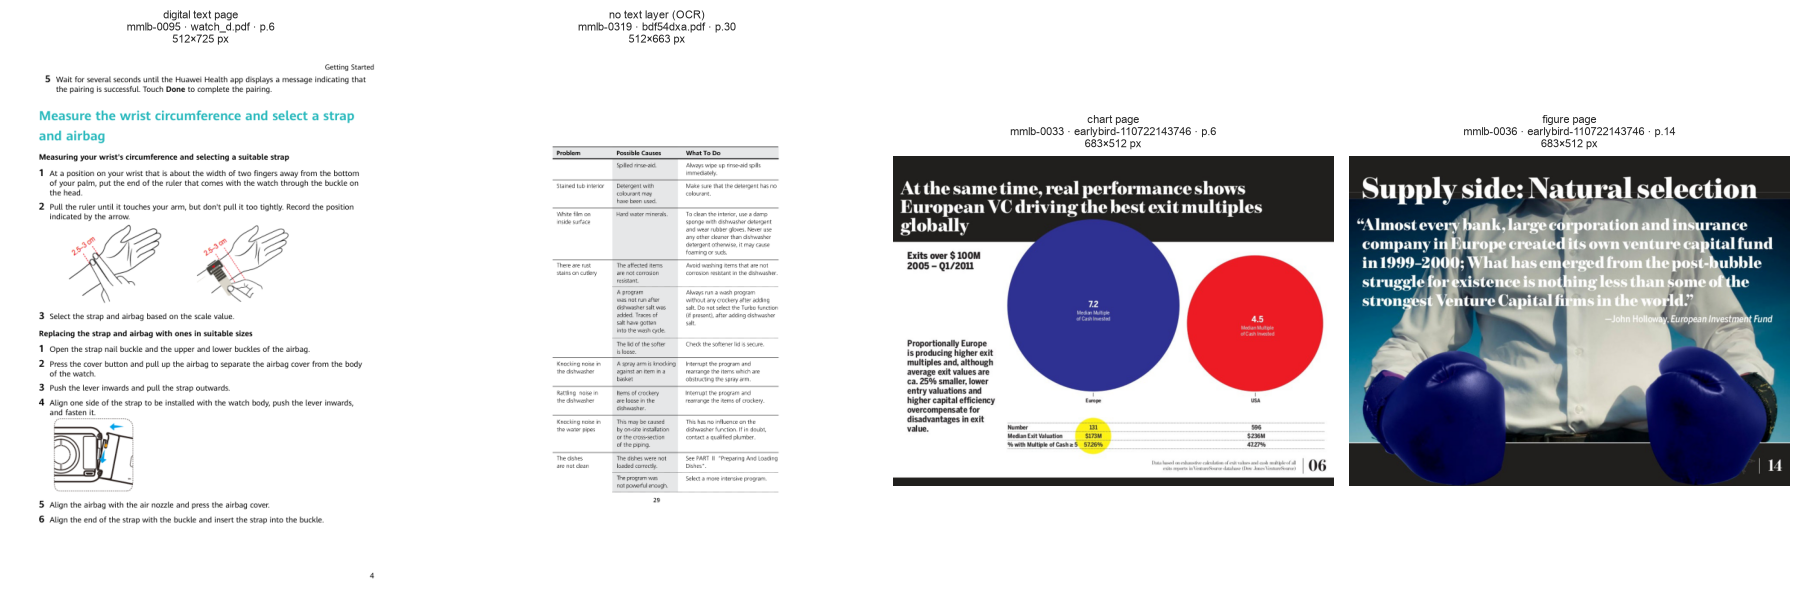

--- digital text page (native):  Getting Started 5 Wait for several seconds until the Huawei Health app displays a message indicating that the pairing is successful. Touch Done to complete the pairing. Measure the wrist circumference and select a strap and airbag Measurin
--- no text layer (OCR) (OCR): Problem Possible Causes What To Do Spilled rinse-aid. Always wipe up rinse-aid spills immediately. Stained tub interior Detergent with Make sure that the detergent has no colourant may colourant. have been used. White film on Hard water min
--- chart page (OCR): At the same time,e real performanceGg shows European VCa | drivingee the best exito multiplese globally Exits over $ 100M 2005 - Q1/2011 7.2 Median Multiple of Cash Invested 45 Median Multiple of Cash Invested Proportionally Europe is produ
--- figure page (OCR): Supply side: Naturalselection ? ‘ >a ¢ ance“Almost everyh company ink f italfund in 1999-2000; \ postbubble struggle forexiste : e stronge } sj ature Capita i j | 14


In [9]:
evidence_candidates = [(r.qid, r.doc_id, p, r.evidence_sources) for r in subset[subset["answerable"]].itertuples() for p in r.evidence_pages]
SELECTION_RULES = {
    "digital text page": lambda d, p, s: page_lookup.loc[(d, p), "native_words"] >= 30 and "Pure-text (Plain-text)" in s,
    "no text layer (OCR)": lambda d, p, s: page_lookup.loc[(d, p), "ocr_used"] and not VISUAL_SOURCES & set(s),
    "chart page": lambda d, p, s: "Chart" in s,
    "figure page": lambda d, p, s: "Figure" in s,
}
representative, used = {}, set()
for label, rule in SELECTION_RULES.items():
    for qid, doc_id, page_number, sources in evidence_candidates:
        if (doc_id, page_number) not in used and rule(doc_id, page_number, sources):
            representative[label] = (qid, doc_id, page_number)
            used.add((doc_id, page_number))
            break


def png_pixels(png):
    pixmap = pymupdf.Pixmap(png)
    return np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n)


fig, axes = plt.subplots(1, len(representative), figsize=(4.6 * len(representative), 6.0))
for ax, (label, (qid, doc_id, page_number)) in zip(axes, representative.items()):
    pixels = png_pixels(page_png(doc_id, page_number))
    ax.imshow(pixels)
    ax.set_title(f"{label}\n{qid} · {doc_id[:22]} · p.{page_number}\n{pixels.shape[1]}×{pixels.shape[0]} px", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()
for label, (qid, doc_id, page_number) in representative.items():
    text = page_lookup.loc[(doc_id, page_number), "text"]
    print(f"--- {label} ({'OCR' if page_lookup.loc[(doc_id, page_number), 'ocr_used'] else 'native'}): {re.sub(r'\s+', ' ', text)[:240]}")

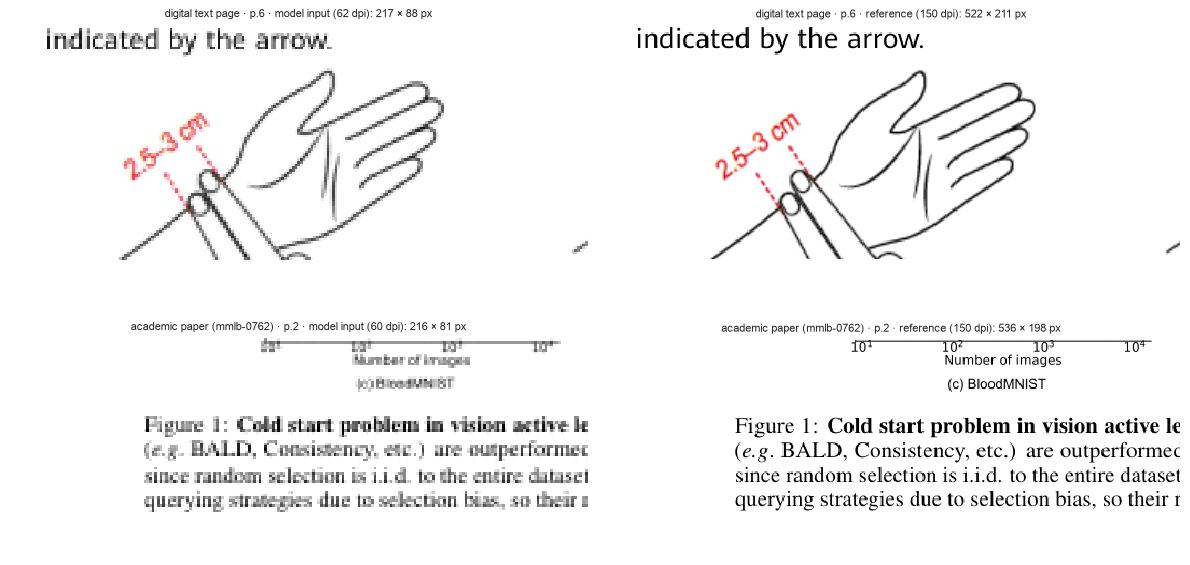

In [10]:
# Fine detail: the same region at the model's resolution and at 150 dpi, shown at the same display size.
paper = next((q, d, p) for q, d, p, _ in evidence_candidates if subset.set_index("qid").loc[q, "doc_type"] == "Academic paper")
crop_cases = [("digital text page", *representative["digital text page"][1:]), (f"academic paper ({paper[0]})", paper[1], paper[2])]
fig, axes = plt.subplots(len(crop_cases), 2, figsize=(12, 3.4 * len(crop_cases)))
for (label, doc_id, page_number), row_axes in zip(crop_cases, axes):
    zoom = manifest.loc[(doc_id, page_number), "zoom"]
    with pymupdf.open(PDF_DIR / doc_id) as pdf:
        page = pdf[page_number - 1]
        r = page.rect
        region = pymupdf.Rect(r.x0 + 0.08 * r.width, r.y0 + 0.30 * r.height, r.x0 + 0.50 * r.width, r.y0 + 0.42 * r.height)
        crops = {f"model input ({72 * zoom:.0f} dpi)": page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), clip=region, alpha=False),
                 "reference (150 dpi)": page.get_pixmap(dpi=150, clip=region, alpha=False)}
    for ax, (resolution, pixmap) in zip(row_axes, crops.items()):
        ax.imshow(np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n), interpolation="nearest")
        ax.set_title(f"{label} · p.{page_number} · {resolution}: {pixmap.width} × {pixmap.height} px", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

- **Slides keep what OCR destroys.** On the chart page (`mmlb-0033`) the image shows bubbles labelled 7.2 and 4.5 and a small table with `$173M` and `$236M`; the OCR text reads `… 7.2 … 45` and loses which number belongs where. On the figure page, a white-on-photo quote is legible in the image but garbled by OCR.
- **Some evidence exists only as graphics.** On the digital text page (`watch_d` p.6, question `mmlb-0095`), the answer "2.5–3 cm" is a red label inside the drawing and is absent from the text layer.
- **The cost of ≈ 60 dpi.** In the crops, manual and paper text are readable by eye but blurred, and small tick labels degrade. For questions that hinge on a small word or digit, the image conditions may be **disadvantaged** against exact native text. 03 measures this per document.

## 5. Token and cost budget, before any call

Prompt tokens = text tokens (system prompt, question, page tags; `tiktoken` `o200k_base` plus 9 tokens of chat formatting) + image tokens (tile formula above). Two resizing rules were possible: `downscale_only` (our 512-px renders cost 2 tiles) and `upscale_to_768` (4–6 tiles whatever we render). The smoke test of the frozen run measured `downscale_only`; a new live run measures it again before any batch.

In [11]:
TILE_RULES = ("downscale_only", "upscale_to_768")
ENCODING = tiktoken.get_encoding("o200k_base")
MESSAGE_OVERHEAD_TOKENS = 9


def tiles_for(width, height, rule):
    scale = min(1.0, 2048 / max(width, height))  # 1. fit within 2048 x 2048 (reduction only)
    width, height = width * scale, height * scale
    short_scale = 768 / min(width, height)  # 2. shortest side -> 768 px
    if rule == "upscale_to_768" or short_scale < 1:
        width, height = width * short_scale, height * short_scale
    return ceil(round(width, 6) / 512) * ceil(round(height, 6) / 512)  # 3. count 512-px tiles


def estimate_request(question, pages_list, dims, rule):
    text_tokens = sum(len(ENCODING.encode(t)) for t in [IMAGE_SYSTEM_PROMPT, image_header(question), *map(page_tag, pages_list)]) + MESSAGE_OVERHEAD_TOKENS
    image_tokens = sum(SETTINGS["image_base_tokens"] + SETTINGS["image_tile_tokens"] * tiles_for(w, h, rule) for w, h in dims)
    prompt_tokens = text_tokens + image_tokens
    return {"prompt_tokens": prompt_tokens, "fits_context": prompt_tokens + SETTINGS["max_output_tokens"] <= SETTINGS["context_window_tokens"],
            "cost_usd_upper": (prompt_tokens * SETTINGS["price_usd_per_1m_input_tokens"] + SETTINGS["max_output_tokens"] * SETTINGS["price_usd_per_1m_output_tokens"]) / 1e6}


def page_dims(doc_id, pages_list):
    return [tuple(manifest.loc[(doc_id, p), ["width_px", "height_px"]]) for p in pages_list]


# Hand checks against OpenAI's documented gpt-4o examples (85 + 170 per tile), which hold under both rules.
for rule in TILE_RULES:
    assert tiles_for(1024, 1024, rule) == 4 and tiles_for(2048, 4096, rule) == 6
assert tiles_for(512, 512, "downscale_only") == 1 and tiles_for(512, 512, "upscale_to_768") == 4

estimates = pd.DataFrame([
    {"qid": r.qid, "condition": name, "rule": rule, "pages": len(getattr(r, CONDITIONS[name]["pages"])), "pilot": r.qid in pilot_qids,
     **estimate_request(r.question, getattr(r, CONDITIONS[name]["pages"]), page_dims(r.doc_id, getattr(r, CONDITIONS[name]["pages"])), rule)}
    for name in ("B", "D") for r in subset.itertuples() if getattr(r, CONDITIONS[name]["pages"]) for rule in TILE_RULES
])
budget = estimates.groupby(["rule", "condition"]).apply(lambda f: pd.Series({
    "requests": len(f), "fit the context": int(f["fits_context"].sum()),
    "tokens per request (min / max)": f"{f['prompt_tokens'].min():,} / {f['prompt_tokens'].max():,}",
    "cost upper bound, full (USD)": round(f.loc[f["fits_context"], "cost_usd_upper"].sum(), 3),
    "cost upper bound, pilot (USD)": round(f.loc[f["fits_context"] & f["pilot"], "cost_usd_upper"].sum(), 3),
}), include_groups=False)
display(budget)
estimates[(estimates["rule"] == "downscale_only") & ~estimates["fits_context"]][["qid", "condition", "pages", "prompt_tokens"]]

requests  fit the context tokens per request (min / max)  cost upper bound, full (USD)  cost upper bound, pilot (USD)
rule           condition                                                                                                                       
downscale_only B                57               57                71,023 / 71,072                         0.621                          0.054
               D                40               38               71,025 / 184,411                         0.414                          0.044
upscale_to_768 B                57                0              127,696 / 184,412                         0.000                          0.000
               D                40                0              127,696 / 479,095                         0.000                          0.000

,qid,condition,pages,prompt_tokens
118,mmlb-0035,D,13,184411
124,mmlb-0039,D,10,141891


- Under `downscale_only`, every page costs 14,167 tokens and a 5-page request ≈ 71k. All 57 B requests and 38 of 40 D requests fit; the two counting questions with 13 and 10 evidence pages (`mmlb-0035`, `mmlb-0039`, ≈ 184k and 142k tokens) are **skipped by protocol** in D. Upper bound ≈ $1.04 for B + D.
- Under `upscale_to_768` no request fits 128k: the design would be infeasible with this model, and the batch gate refuses to start.
- The text conditions used ≈ 1.9k prompt tokens per question; images multiply input tokens by ≈ 37.

## 6. API plumbing

Readiness checks, the reply parser, error classification, bounded retries, token pacing, the response cache and one generator for all four conditions. The parser is tested on fixed strings first; these are interface tests and never enter results.

In [12]:
try:
    import openai
except ImportError:
    openai = None


def parse_model_output(raw_text):
    # Return (prediction, cited_pages, error_message_or_None).
    try:
        payload = json.loads(raw_text)
        answer = payload["answer"]
        cited = [int(page) for page in payload.get("cited_pages", [])]
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        return "", [], f"unparseable model output: {error}"
    if isinstance(answer, str) and answer.strip().lower() == "not answerable":
        answer = "Not answerable"  # the F1 formula compares this exact string
    return answer, cited, None


assert parse_model_output('{"answer": "not answerable", "cited_pages": []}') == ("Not answerable", [], None)
assert parse_model_output('{"answer": 12, "cited_pages": ["4"]}') == (12, [4], None)
assert parse_model_output('{"answer": ["Circle", "Rectangle"], "cited_pages": [3, 7]}') == (["Circle", "Rectangle"], [3, 7], None)
assert parse_model_output('{"answer": 2.5}') == (2.5, [], None)  # missing cited_pages -> no citation, not an error
assert parse_model_output("The answer is 12 [Page 4]")[2].startswith("unparseable")  # prose instead of JSON
assert parse_model_output('{"cited_pages": [4]}')[2].startswith("unparseable")  # no answer key
assert parse_model_output('{"answer": "Europe IPO", "cited_pa')[2].startswith("unparseable")  # cut off by max tokens
assert parse_model_output('{"answer": 5, "cited_pages": ["page 4"]}')[2].startswith("unparseable")  # non-integer page

QUOTA_CODES = {"insufficient_quota", "credit_balance_exhausted", "billing_hard_limit_reached", "billing_not_active"}
SECRET_PATTERN = re.compile(r"sk-[A-Za-z0-9_\-\*]{4,}")


def sanitize(text, limit=300):
    return SECRET_PATTERN.sub("sk-<redacted>", str(text))[:limit]  # 401 messages echo part of the key


def classify_api_error(error):
    # (category, retryable) from the exception class and the structured API code, never from the free-text message.
    if isinstance(error, openai.RateLimitError):
        if getattr(error, "code", None) in QUOTA_CODES or getattr(error, "type", None) in QUOTA_CODES:
            return "quota_or_billing", False  # same HTTP 429 as a rate limit, but waiting will not help
        return "rate_limit", True
    if isinstance(error, openai.AuthenticationError):
        return "authentication", False
    if isinstance(error, openai.PermissionDeniedError):
        return "permission", False
    if isinstance(error, openai.NotFoundError):
        return "model_access", False
    if isinstance(error, (openai.BadRequestError, openai.UnprocessableEntityError)):
        return "invalid_request", False
    if isinstance(error, openai.APIConnectionError):  # includes APITimeoutError
        return "network", True
    if isinstance(error, openai.InternalServerError) or (isinstance(error, openai.APIStatusError) and error.status_code in (408, 409)):
        return "server", True
    return "unexpected", False


def describe_api_error(error):
    category, retryable = classify_api_error(error)
    return {"category": category, "retryable": retryable, "exception": type(error).__name__, "status_code": getattr(error, "status_code", None),
            "code": getattr(error, "code", None), "type": getattr(error, "type", None), "message": sanitize(getattr(error, "message", error)),
            "request_id": getattr(error, "request_id", None)}


def call_with_retries(create, request, max_attempts=SETTINGS["max_attempts"], sleep=time.sleep):
    # Retry only transient errors, waiting 2 s, 4 s, ... Exceptions that are not API errors (bugs) propagate.
    failures = []
    for attempt in range(1, max_attempts + 1):
        started = time.perf_counter()
        try:
            return create(**request), failures, round(time.perf_counter() - started, 3)
        except openai.OpenAIError as error:
            latency = round(time.perf_counter() - started, 3)
            failures.append(describe_api_error(error))
            if not failures[-1]["retryable"] or attempt == max_attempts:
                return None, failures, latency
            sleep(2**attempt)


RESPONSE_FIELDS = ("raw_response", "finish_reason", "served_model", "system_fingerprint", "prompt_tokens", "completion_tokens", "cached_prompt_tokens")


def response_fields(response):
    usage = response.usage
    details = getattr(usage, "prompt_tokens_details", None) if usage else None
    return {"raw_response": response.choices[0].message.content or "", "finish_reason": response.choices[0].finish_reason,
            "served_model": response.model, "system_fingerprint": getattr(response, "system_fingerprint", None), "prompt_tokens": usage.prompt_tokens if usage else None,
            "completion_tokens": usage.completion_tokens if usage else None, "cached_prompt_tokens": getattr(details, "cached_tokens", None)}


print("openai", getattr(openai, "__version__", "not installed"), "| parser checks passed")

openai 2.54.0 | parser checks passed


In [13]:
class TokenPacer:
    # Keeps the estimated prompt tokens sent in any 60-second window under `tokens_per_minute` (one image request is ~71k tokens).
    def __init__(self, tokens_per_minute, clock=time.monotonic, sleep=time.sleep):
        self.tokens_per_minute, self.clock, self.sleep = tokens_per_minute, clock, sleep
        self.window, self.waited_s = deque(), 0.0

    def wait(self, tokens):
        while True:
            now = self.clock()
            while self.window and now - self.window[0][0] >= 60:
                self.window.popleft()
            if not self.window or sum(t for _, t in self.window) + tokens <= self.tokens_per_minute:
                break
            pause = 60 - (now - self.window[0][0])
            self.sleep(pause)
            self.waited_s += pause
        self.window.append((self.clock(), tokens))


RESPONSE_CACHE_PATH = CACHE_DIR / "vision_response_cache.jsonl"  # image replies only (text requests are cheap and not cached)


def load_response_cache(path):
    return {record["fingerprint"]: record for record in read_jsonl(path)} if path.is_file() else {}


def append_to_cache(path, fingerprint, fields, latency):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "a") as handle:
        handle.write(json.dumps({"fingerprint": fingerprint, "saved_at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "latency_s": latency, **fields}) + "\n")


SKIPPED_BY_PROTOCOL = {"skipped_context_limit"}


def generate(rows, condition, create, *, tile_rule="downscale_only", pacer=None, cache=None, cache_path=None, sleep=time.sleep):
    # One record per question (never Base64). For each question, in order: an image request too large for the context is
    # skipped without a call; after a failed call the batch is stopped and later questions are 'not_attempted'; an identical
    # cached request is reused; otherwise the request is paced (images), sent with bounded retries, and cached.
    spec = CONDITIONS[condition]
    is_image = spec["representation"] == "image"
    records, stop_reason = [], None
    for row in rows:
        pages_list = list(getattr(row, spec["pages"]))
        record = {"condition": condition, "qid": row.qid, "supplied_pages": pages_list, "requested_model": SETTINGS["model_name"],
                  "status": "not_attempted", "source": None, "pred": "", "cited_pages": [], "raw_response": None}
        estimate = None
        if is_image:
            estimate = estimate_request(row.question, pages_list, page_dims(row.doc_id, pages_list), tile_rule)
            record.update(image_detail=SETTINGS["image_detail"], render=RENDER_LABEL, tile_rule=tile_rule, estimated_prompt_tokens=estimate["prompt_tokens"])
            if not estimate["fits_context"]:
                record["status"] = "skipped_context_limit"  # decided from page count and image sizes only, before any call
        if record["status"] == "not_attempted" and stop_reason is None:
            request = build_condition_request(spec["representation"], row.question, row.doc_id, pages_list)
            record["fingerprint"] = request_fingerprint(request)
            if is_image:
                record["image_sha256"] = [p["sha256"][:16] for p in loggable(request)["messages"][1]["content"] if p.get("type") == "image"]
            cached = cache.get(record["fingerprint"]) if cache is not None and SETTINGS["reuse_cached_responses"] else None
            if cached is not None:
                record.update({f: cached.get(f) for f in RESPONSE_FIELDS}, source="cache", attempts=0, latency_s=cached.get("latency_s"), failed_attempts=[])
            else:
                if pacer is not None and estimate is not None:
                    pacer.wait(estimate["prompt_tokens"])
                response, failures, latency = call_with_retries(create, request, sleep=sleep)
                record.update(source="live", attempts=len(failures) + (response is not None), latency_s=latency, failed_attempts=failures)
                if response is None:
                    record.update(status="api_error", error_category=failures[-1]["category"])
                    stop_reason = f"{failures[-1]['category']} at {row.qid} after {len(failures)} attempt(s)"
                else:
                    fields = response_fields(response)
                    record.update(fields)
                    if cache is not None:
                        cache[record["fingerprint"]] = {**fields, "latency_s": latency}
                        if cache_path is not None:
                            append_to_cache(cache_path, record["fingerprint"], fields, latency)
            if record["raw_response"] is not None:
                pred, cited, parse_error = parse_model_output(record["raw_response"])
                record.update(pred=pred, cited_pages=cited, parse_error=parse_error, status="ok" if parse_error is None else "parse_error")
        records.append(record)
    return records, stop_reason


def generation_outcome(records, population_qids):
    # Complete = every question not skipped by protocol received a reply (ok, or parse_error = the model's own failure).
    status = pd.Series({r["qid"]: r["status"] for r in records}, dtype=object).reindex(population_qids).fillna("not_attempted")
    considered = status[~status.isin(SKIPPED_BY_PROTOCOL)]
    return bool(len(considered)) and bool(considered.isin(["ok", "parse_error"]).all()), status.value_counts().to_dict()


def populations(mode):
    # The questions each condition answers: pilot or full subset; C and D only answerable questions with evidence.
    base = subset[subset["qid"].isin(pilot_qids)] if mode == "pilot" else subset
    return {name: base[base[spec["pages"]].notna()] for name, spec in CONDITIONS.items()}


def run_conditions(mode, create, *, text_ready, image_ready, tile_rule, pacer=None, cache=None, cache_path=None, sleep=time.sleep):
    # A, then C (only if A completed); B, then D (only if B completed). Returns records and a status per condition.
    population = populations(mode)
    records, status = {}, {}
    for first, second, ready, use_cache in (("A", "C", text_ready, False), ("B", "D", image_ready, True)):
        previous_complete = ready
        for name in (first, second):
            records[name] = []
            if not previous_complete:
                status[name] = "skipped: gate closed or prerequisite incomplete (no API call)"
                continue
            records[name], stop = generate(population[name].itertuples(), name, create, tile_rule=tile_rule, pacer=pacer,
                                           cache=cache if use_cache else None, cache_path=cache_path if use_cache else None, sleep=sleep)
            complete, counts = generation_outcome(records[name], population[name]["qid"].tolist())
            status[name] = f"complete: {counts}" if complete else f"incomplete: stopped by {stop}; no metric"
            previous_complete = complete
    return records, status


print("Pacing, response cache and generator defined.")

Pacing, response cache and generator defined.


## 7. Offline tests with mocked API responses

No request leaves the machine. The mocks are real SDK exception and `ChatCompletion` objects built from fixed bodies; the credit-exhausted body is the one recorded by an earlier failed run (`20261119T210333Z_84cb44ab`, whose 57 failed calls were first scored as wrong answers, which is why every rule above exists). The questions and page images are real; only the replies are mocked, and none of them enters a result.

In [14]:
import httpx
from openai.types.chat import ChatCompletion

MOCK_REQUEST = httpx.Request("POST", "https://api.openai.com/v1/chat/completions")


def mock_status_error(cls, status, body):
    return cls(f"Error code: {status} - {body}", response=httpx.Response(status, request=MOCK_REQUEST, headers={"x-request-id": "req_mock"}), body=body)


def mock_completion(content, finish_reason="stop", prompt_tokens=100, system_fingerprint="fp_mock"):
    return ChatCompletion.model_validate({
        "id": "chatcmpl-mock", "object": "chat.completion", "created": 0, "model": "mock-model-snapshot", "system_fingerprint": system_fingerprint,
        "choices": [{"index": 0, "finish_reason": finish_reason, "message": {"role": "assistant", "content": content}}],
        "usage": {"prompt_tokens": prompt_tokens, "completion_tokens": 10, "total_tokens": prompt_tokens + 10, "prompt_tokens_details": {"cached_tokens": 0}},
    })


def scripted(*outcomes):
    # Stand-in for client.chat.completions.create: replays outcomes in order (the last one repeats) and records each request.
    calls = []

    def create(**request):
        calls.append(request)
        outcome = outcomes[min(len(calls), len(outcomes)) - 1]
        if isinstance(outcome, Exception):
            raise outcome
        return outcome

    return create, calls


QUOTA_BODY = {"message": "You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.",
              "type": "insufficient_quota", "param": None, "code": "credit_balance_exhausted"}
quota_error = mock_status_error(openai.RateLimitError, 429, QUOTA_BODY)
rate_error = mock_status_error(openai.RateLimitError, 429, {"message": "Rate limit reached for tokens", "type": "tokens", "param": None, "code": "rate_limit_exceeded"})
server_error = mock_status_error(openai.InternalServerError, 500, {"message": "The server had an error.", "type": "server_error", "param": None, "code": None})
auth_error = mock_status_error(openai.AuthenticationError, 401, {"message": "Incorrect API key provided: sk-proj-abcd****wxyz.", "type": "invalid_request_error", "param": None, "code": "invalid_api_key"})
cases = [
    ("credits exhausted (real body)", quota_error, "quota_or_billing", False),
    ("ordinary rate limit", rate_error, "rate_limit", True),
    ("invalid key", auth_error, "authentication", False),
    ("project lacks permission", mock_status_error(openai.PermissionDeniedError, 403, {"message": "No access.", "type": "invalid_request_error", "param": None, "code": None}), "permission", False),
    ("model not available", mock_status_error(openai.NotFoundError, 404, {"message": "No such model.", "type": "invalid_request_error", "param": None, "code": "model_not_found"}), "model_access", False),
    ("unsupported parameter / invalid image", mock_status_error(openai.BadRequestError, 400, {"message": "Invalid image.", "type": "invalid_request_error", "param": None, "code": "invalid_image"}), "invalid_request", False),
    ("timeout", openai.APITimeoutError(request=MOCK_REQUEST), "network", True),
    ("connection reset", openai.APIConnectionError(request=MOCK_REQUEST), "network", True),
    ("server error", server_error, "server", True),
]
error_table = pd.DataFrame([{"case": n, "exception": type(e).__name__, "category": classify_api_error(e)[0], "retry": classify_api_error(e)[1],
                             "ok": classify_api_error(e) == (c, r)} for n, e, c, r in cases])
display(error_table)
assert error_table["ok"].all() and "abcd" not in describe_api_error(auth_error)["message"], "classification or key redaction failed"

,case,exception,category,retry,ok
0,credits exhausted (real body),RateLimitError,quota_or_billing,False,True
1,ordinary rate limit,RateLimitError,rate_limit,True,True
2,invalid key,AuthenticationError,authentication,False,True
3,project lacks permission,PermissionDeniedError,permission,False,True
4,model not available,NotFoundError,model_access,False,True
5,unsupported parameter / invalid image,BadRequestError,invalid_request,False,True
6,timeout,APITimeoutError,network,True,True
7,connection reset,APIConnectionError,network,True,True
8,server error,InternalServerError,server,True,True


In [15]:
rows = list(subset[subset["qid"].isin(["mmlb-0033", "mmlb-0034", "mmlb-0038", "mmlb-0041"])].itertuples())
qids = [r.qid for r in rows]
no_sleep = lambda seconds: None

# A. Credits exhausted on question 1: exactly one request (the SDK default would have retried), the rest not attempted, metrics gated.
create, calls = scripted(quota_error)
records, stop = generate(rows, "A", create, sleep=no_sleep)
assert len(calls) == 1 and [r["status"] for r in records] == ["api_error"] + ["not_attempted"] * 3
assert stop.startswith("quota_or_billing") and generation_outcome(records, qids)[0] is False

# B. Transient rate limit then success: one retry after 2 s (image condition).
waits = []
create, calls = scripted(rate_error, mock_completion('{"answer": 63, "cited_pages": [6]}'))
records, stop = generate(rows[:1], "B", create, sleep=waits.append)
assert stop is None and len(calls) == 2 and waits == [2] and records[0]["attempts"] == 2 and records[0]["status"] == "ok"

# C. Persistent server error: bounded at max_attempts requests (2 s, 4 s), then the batch stops.
waits = []
create, calls = scripted(server_error)
records, stop = generate(rows[:2], "A", create, sleep=waits.append)
assert len(calls) == SETTINGS["max_attempts"] == 3 and waits == [2, 4] and [r["status"] for r in records] == ["api_error", "not_attempted"]

# D. Replies: an answer, an abstention, and truncated JSON (a model failure: parse_error, kept and later scored 0).
create, calls = scripted(mock_completion('{"answer": 63, "cited_pages": [6]}'), mock_completion('{"answer": "not answerable", "cited_pages": []}'),
                         mock_completion('{"answer": "Europe IPO", "cited_pa', finish_reason="length"))
records, stop = generate(rows[:3], "A", create)
assert [r["status"] for r in records] == ["ok", "ok", "parse_error"] and records[1]["pred"] == "Not answerable"
assert records[0]["served_model"] == "mock-model-snapshot" and records[0]["prompt_tokens"] == 100 and records[2]["finish_reason"] == "length"
assert generation_outcome(records, qids[:3]) == (True, {"ok": 2, "parse_error": 1})
assert generation_outcome(records, qids)[0] is False  # a population question without a record counts as not attempted

# E. Text requests: configured parameters; condition A sends the BM25 pages, condition C the oracle pages, labelled in order.
sent = calls[0]
assert sent["model"] == SETTINGS["model_name"] and sent["response_format"] == {"type": "json_object"} and sent["temperature"] == 0.0
assert sent["max_completion_tokens"] == 400 and sent["messages"][0]["content"] == TEXT_SYSTEM_PROMPT
assert sent["messages"][1]["content"] == build_user_message(rows[0].question, rows[0].doc_id, rows[0].retrieved_pages)
oracle_row = next(subset[subset["qid"] == "mmlb-0037"].itertuples())
create, calls = scripted(mock_completion('{"answer": 1}'))
generate([oracle_row], "C", create)
assert re.findall(r"\[Page (\d+)\]", calls[0]["messages"][1]["content"]) == [str(p) for p in oracle_row.oracle_pages]

# F. Image requests: one image per supplied page, in order, at the configured detail; records carry no Base64.
create, calls = scripted(mock_completion('{"answer": 1}', prompt_tokens=71_000))
records, _ = generate(rows[:1], "B", create)
images = [p for p in calls[0]["messages"][1]["content"] if p["type"] == "image_url"]
assert calls[0]["messages"][0]["content"] == IMAGE_SYSTEM_PROMPT and len(images) == gen_k and {p["image_url"]["detail"] for p in images} == {"high"}
assert "base64" not in json.dumps(records) and "data:image" not in json.dumps(records)

# G. Response cache: a second pass makes zero calls and returns identical predictions; the cache file has no Base64.
with tempfile.TemporaryDirectory() as folder:
    cache_file, cache = Path(folder) / "cache.jsonl", {}
    create, calls = scripted(mock_completion('{"answer": 63, "cited_pages": [6]}'), mock_completion('{"answer": "Not answerable", "cited_pages": []}'))
    first, _ = generate(rows[:2], "B", create, cache=cache, cache_path=cache_file)
    create_again, calls_again = scripted(server_error)  # would fail if it were called
    second, _ = generate(rows[:2], "B", create_again, cache=load_response_cache(cache_file))
    assert len(calls) == 2 and not calls_again and [r["pred"] for r in first] == [r["pred"] for r in second]
    assert [r["source"] for r in second] == ["cache", "cache"] and "base64" not in cache_file.read_text()

# H. Context limit: the 13-page oracle request is skipped without a call and leaves the denominator by protocol.
create, calls = scripted(mock_completion('{"answer": 1}'))
records, _ = generate(subset[subset["qid"] == "mmlb-0035"].itertuples(), "D", create)
assert records[0]["status"] == "skipped_context_limit" and not calls
assert generation_outcome(records + [{"qid": "x", "status": "ok"}], ["mmlb-0035", "x"]) == (True, {"skipped_context_limit": 1, "ok": 1})

# I. Pacer: budget 100k/min, three 60k requests -> the 2nd and 3rd each wait for the window to clear.
clock, pacer_waits = [0.0], []
def fake_sleep(seconds):
    pacer_waits.append(round(seconds, 6))
    clock[0] += seconds
pacer = TokenPacer(100_000, clock=lambda: clock[0], sleep=fake_sleep)
for _ in range(3):
    pacer.wait(60_000)
assert pacer_waits == [60.0, 60.0]

# J. A bug in our own code is not mistaken for an API failure: it propagates.
def broken_create(**request):
    raise KeyError("bug")
try:
    generate(rows[:1], "A", broken_create)
    raise AssertionError("a non-API exception was swallowed")
except KeyError:
    pass

# K. End-to-end orchestration of a full run with a mocked client: populations, ordering, skips and prerequisites.
create, calls = scripted(mock_completion('{"answer": 1, "cited_pages": []}'))
mock_records, mock_status = run_conditions("full", create, text_ready=True, image_ready=True, tile_rule="downscale_only")
assert {name: len(r) for name, r in mock_records.items()} == {"A": 57, "C": 40, "B": 57, "D": 40} and len(calls) == 57 + 40 + 57 + 38
assert sum(r["status"] == "skipped_context_limit" for r in mock_records["D"]) == 2
create, calls = scripted(quota_error)
mock_records, mock_status = run_conditions("pilot", create, text_ready=True, image_ready=False, tile_rule="downscale_only")
assert len(calls) == 1 and mock_status["C"].startswith("skipped") and mock_status["B"].startswith("skipped") and not mock_records["D"]

print("Mocked tests passed: classification and redaction, quota stop, bounded retries, parsing, text and image request content, "
      "Base64-free records, response cache, context-limit skip, pacing, bug propagation, full-run orchestration.")

Mocked tests passed: classification and redaction, quota stop, bounded retries, parsing, text and image request content, Base64-free records, response cache, context-limit skip, pacing, bug propagation, full-run orchestration.


## 8. Produce the predictions

**Replay** (default) reuses the frozen replies, but only after checking that the experiment rebuilt here is the experiment that was run: same page lists (Step 1), same prompts (Steps 2–3), same served model snapshot, and for every image reply the **request fingerprint** recomputed now (model, parameters, prompt, question, page tags and image SHA-256) equals the one recorded when the request was sent.

The two live cells below run only when `VISUALDOC_QA_MODE` is `smoke`, `pilot` or `full`. They first send one text and one image smoke request with known answers (expected reply `2019`, citing page 1); the image smoke also measures which tile rule the API applies and the account's tokens-per-minute limit. Batches start only if every gate condition holds.

In [16]:
predictions, statuses, provenance = {}, {}, {}
if MODE == "replay":
    for name, spec in CONDITIONS.items():
        records = frozen_records[name]
        replies = [r for r in records if r["status"] not in SKIPPED_BY_PROTOCOL]
        assert all(r["status"] == "ok" for r in replies), f"{name}: a frozen reply is not ok"
        assert {r["served_model"] for r in replies} == {SETTINGS["model_name"]}, f"{name}: served by another snapshot"
        if spec["representation"] == "image":
            for r in records:
                row = pages_by_qid.loc[r["qid"]]
                estimate = estimate_request(row["question"], r["supplied_pages"], page_dims(row["doc_id"], r["supplied_pages"]), "downscale_only")
                assert r["estimated_prompt_tokens"] == estimate["prompt_tokens"], (name, r["qid"])
                assert (r["status"] in SKIPPED_BY_PROTOCOL) == (not estimate["fits_context"]), (name, r["qid"])
                if r["status"] not in SKIPPED_BY_PROTOCOL:
                    rebuilt = build_condition_request("image", row["question"], row["doc_id"], r["supplied_pages"])
                    assert request_fingerprint(rebuilt) == r["fingerprint"], f"{name} {r['qid']}: rebuilt request differs from the request sent"
        predictions[name] = [{**r, "condition": name} for r in records]
        statuses[name] = f"replayed: {dict(Counter(r['status'] for r in records))}"
        provenance[name] = str(spec["frozen"].relative_to(PROJECT_ROOT))
    # The text runs requested the alias 'gpt-4o-mini' (served by the snapshot above) with the same generation parameters.
    for key in ("temperature", "max_output_tokens", "generation_top_k", "max_chars_per_page"):
        assert frozen_text_settings[key] == SETTINGS[key] == frozen_image_settings.get(key, SETTINGS[key]), key
    assert {r["requested_model"] for name in "AC" for r in frozen_records[name]} == {"gpt-4o-mini"}
    print("Replay checks passed: page lists, prompts, parameters, served snapshot, token estimates and all "
          f"{sum(r['status'] == 'ok' for n in 'BD' for r in frozen_records[n])} image request fingerprints match the frozen runs.")
    display(pd.DataFrame({CONDITIONS[n]["label"]: {"status": statuses[n], "source": provenance[n]} for n in CONDITIONS}).T)
else:
    print(f"Mode {MODE!r}: frozen predictions are not replayed; see the live cells below.")

Replay checks passed: page lists, prompts, parameters, served snapshot, token estimates and all 95 image request fingerprints match the frozen runs.


,status,source
"A. text, retrieved",replayed: {'ok': 57},experiments/frozen/mmlongbench_doc/text_run_20261119T220858Z_a351a...
"B. images, retrieved",replayed: {'ok': 57},experiments/frozen/mmlongbench_doc/image_run_20261119T232847Z_65cc...
"C. text, oracle",replayed: {'ok': 40},experiments/frozen/mmlongbench_doc/text_run_20261119T220858Z_a351a...
"D. images, oracle","replayed: {'ok': 38, 'skipped_context_limit': 2}",experiments/frozen/mmlongbench_doc/image_run_20261119T232847Z_65cc...


In [17]:
smoke = {"text": {"status": "not run"}, "image": {"status": "not run"}}
client, RATE_LIMIT_HEADERS, MEASURED_TILE_RULE = None, {}, None
if MODE == "replay":
    print("Replay mode: no smoke test, no API call.")
else:
    readiness = pd.DataFrame([
        ("provider is 'openai'", SETTINGS["model_provider"] == "openai"),
        ("model snapshot set", bool(SETTINGS["model_name"])),
        ("OPENAI_API_KEY present (value never printed)", bool(os.getenv("OPENAI_API_KEY"))),
        ("openai package installed", openai is not None),
    ], columns=["check", "ok"])
    display(readiness)
    if readiness["ok"].all():
        from openai import OpenAI

        client = OpenAI(max_retries=0, timeout=SETTINGS["request_timeout_s"])  # the SDK's silent retries are off

        def create_capturing_headers(**request):
            raw = client.chat.completions.with_raw_response.create(**request)
            RATE_LIMIT_HEADERS.update({k: v for k, v in raw.headers.items() if k.lower().startswith("x-ratelimit-")})
            return raw.parse()

        def smoke_call(request, create):
            response, failures, latency = call_with_retries(create, request)
            record = {"attempts": len(failures) + (response is not None), "latency_s": latency, "failed_attempts": failures}
            if response is None:
                return {**record, "status": "api_error", "error_category": failures[-1]["category"]}
            record.update(response_fields(response))
            pred, cited, error = parse_model_output(record["raw_response"])
            return {**record, "pred": pred, "cited_pages": cited, "status": "ok" if error is None and str(pred) == "2019" else "wrong_or_unparseable"}

        smoke_text = "Question: In which year was the report published?\n\nPage excerpts:\n\n[Page 1]\nThis report was published in 2019 by the research team."
        smoke["text"] = smoke_call(build_request(TEXT_SYSTEM_PROMPT, smoke_text), client.chat.completions.create)
        with pymupdf.open() as smoke_pdf:  # a synthetic letter page with a known answer, rendered in the same box
            page = smoke_pdf.new_page(width=612, height=792)
            page.insert_textbox(pymupdf.Rect(72, 100, 540, 500), "Annual report\n\nThis report was published in 2019 by the research team.", fontsize=28)
            zoom = min(512 / 612, 1024 / 792)
            smoke_png = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False).tobytes("png")
        smoke_question = "In which year was the report published?"
        smoke_request = build_request(IMAGE_SYSTEM_PROMPT, [{"type": "text", "text": image_header(smoke_question)}, {"type": "text", "text": page_tag(1)}, image_part(smoke_png)])
        smoke_dims = [(pymupdf.Pixmap(smoke_png).width, pymupdf.Pixmap(smoke_png).height)]
        predicted = {rule: estimate_request(smoke_question, [1], smoke_dims, rule)["prompt_tokens"] for rule in TILE_RULES}
        smoke["image"] = {**smoke_call(smoke_request, create_capturing_headers), "predicted_prompt_tokens": predicted}
        measured = smoke["image"].get("prompt_tokens")
        matches = [rule for rule, tokens in predicted.items() if measured is not None and abs(measured - tokens) <= 300]  # the rules differ by ~11k
        MEASURED_TILE_RULE = matches[0] if len(matches) == 1 else None
    display(pd.DataFrame({k: {f: v for f, v in s.items() if f not in ("raw_response", "failed_attempts")} for k, s in smoke.items()}).T)
    print("Measured tile rule:", MEASURED_TILE_RULE)

Replay mode: no smoke test, no API call.


In [18]:
if MODE in ("pilot", "full"):
    population = populations(MODE)
    text_ready = smoke["text"]["status"] == "ok"
    limit = RATE_LIMIT_HEADERS.get("x-ratelimit-limit-tokens")
    pacing_tpm = int(0.8 * int(limit)) if limit and str(limit).isdigit() else SETTINGS["default_tokens_per_minute"]
    cache = load_response_cache(RESPONSE_CACHE_PATH)
    live_cost, feasible = 0.0, False
    if MEASURED_TILE_RULE is not None:
        feasible = all(estimate_request(r.question, r.retrieved_pages, page_dims(r.doc_id, r.retrieved_pages), MEASURED_TILE_RULE)["fits_context"]
                       for r in population["B"].itertuples())
        for name in ("B", "D"):
            for r in population[name].itertuples():
                pages_list = getattr(r, CONDITIONS[name]["pages"])
                estimate = estimate_request(r.question, pages_list, page_dims(r.doc_id, pages_list), MEASURED_TILE_RULE)
                fingerprint = request_fingerprint(build_condition_request("image", r.question, r.doc_id, pages_list))
                if estimate["fits_context"] and not (SETTINGS["reuse_cached_responses"] and fingerprint in cache):
                    live_cost += estimate["cost_usd_upper"]
    gate = pd.DataFrame([
        ("text smoke answered 2019", text_ready),
        ("image smoke answered 2019 from the image", smoke["image"]["status"] == "ok"),
        ("image-token rule measured", MEASURED_TILE_RULE is not None),
        ("every B request fits the context", feasible),
        (f"estimated live image cost ${live_cost:.3f} <= ${SETTINGS['max_estimated_live_cost_usd']:.2f}", live_cost <= SETTINGS["max_estimated_live_cost_usd"]),
    ], columns=["gate condition", "ok"])
    display(gate)
    image_ready = bool(gate["ok"].all())
    predictions, statuses = run_conditions(MODE, client.chat.completions.create if client else None, text_ready=text_ready, image_ready=image_ready,
                                           tile_rule=MEASURED_TILE_RULE, pacer=TokenPacer(pacing_tpm), cache=cache, cache_path=RESPONSE_CACHE_PATH)
    run_id = f"{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{MODE}"
    run_dir = RUNS_DIR / run_id
    run_dir.mkdir(parents=True, exist_ok=True)
    (run_dir / "settings.json").write_text(json.dumps({**SETTINGS, "text_prompt_hash": TEXT_PROMPT_HASH, "image_prompt_hash": IMAGE_PROMPT_HASH,
                                                       "measured_tile_rule": MEASURED_TILE_RULE, "rate_limit_headers": RATE_LIMIT_HEADERS,
                                                       "smoke": smoke, "status": statuses}, indent=2, default=str))
    for name, records in predictions.items():
        (run_dir / f"predictions_{name}.jsonl").write_text("".join(json.dumps(r, default=str) + "\n" for r in records))
    provenance = {name: str(run_dir.relative_to(PROJECT_ROOT)) for name in predictions}
    display(pd.Series(statuses, name="status").to_frame())
else:
    print(f"Mode {MODE!r}: no batch is sent.")

Mode 'replay': no batch is sent.


## 9. Save the predictions for evaluation

One JSON-lines file per condition plus a manifest that records where the predictions came from. In `smoke` mode nothing is written, so 03 keeps reading the previous predictions.

In [19]:
PREDICTIONS_DIR = PROCESSED_DIR / "predictions"
if predictions and all(predictions.values()):
    PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
    for name, records in predictions.items():
        text = "".join(json.dumps(r, default=str) + "\n" for r in records)
        assert not SECRET_PATTERN.search(text) and "base64," not in text, f"{name}: a key or an image payload would be saved"
        (PREDICTIONS_DIR / f"{name}.jsonl").write_text(text)
    manifest_record = {
        "mode": MODE, "written_at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "model": SETTINGS["model_name"],
        "text_prompt_hash": TEXT_PROMPT_HASH, "image_prompt_hash": IMAGE_PROMPT_HASH, "pilot_qids": pilot_qids,
        "conditions": {name: {"label": CONDITIONS[name]["label"], "source": provenance[name], "status": statuses[name],
                              "records": len(predictions[name])} for name in CONDITIONS},
    }
    (PREDICTIONS_DIR / "manifest.json").write_text(json.dumps(manifest_record, indent=2))
    display(pd.DataFrame([{"file": p.name, "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(PREDICTIONS_DIR.iterdir())]))
else:
    print("No complete set of predictions in this execution: nothing written.")

,file,KB
0,A.jsonl,24.6
1,B.jsonl,46.2
2,C.jsonl,17.3
3,D.jsonl,31.5
4,manifest.json,1.2


## 10. Experiment E1 — frozen resolution-only oracle comparison

The version-controlled specification is `experiments/specs/e1_image_resolution_v1.json`. Notebook execution derives the population, requests and costs again and asserts that they match the frozen specification before a live client is created.

**Treatment contrast.** Both conditions receive the same annotated evidence pages, in the same order, with the same prompt and generation parameters. Only the PNG pixels change: a 512-px versus 768-px rendered short side. Frozen D is not the control because it adds BM25 padding pages; using it would change both resolution and context.

**Primary outcome.** The single primary outcome is the paired answer-accuracy difference, $n^{-1}\sum_i(\mathrm{correct}_{768,i}-\mathrm{correct}_{512,i})$, on the frozen 37-question matched population. Mean benchmark-score difference is secondary. The nine-question visual-reading subgroup is frozen by question ID from manual labels assigned before E1, and remains mechanism-focused rather than population-generalizable.

**Replicates and order.** `main_r1` is the paired 512/768 comparison. In full mode, `control_r2` repeats every 512-px request as an independent replicate to estimate run-to-run variability. Question order and within-pair order are independently randomized with recorded seeds. All timestamps, global order, model/system fingerprints, image dimensions/hashes and cache provenance are saved.

**Technical gate.** Every paid mode first sends one matched smoke pair. The request bytes are decoded locally and checked against manifest dimensions and SHA-256 hashes. Observed prompt tokens must agree with documented image-token accounting within the frozen tolerance. This verifies accounting and request plumbing; it does **not** prove the model's internal visual resolution. A failed essential gate stops before pilot/full requests.

**Population and pilot.** The context gate retains 37/40 answerable questions and documents the three exclusions rather than changing the population silently. The eight selected pilot questions test parsing, ordering, caching, persistence and heterogeneous page shapes; pilot outcomes are not used to claim statistical improvement.

**Resolution–budget trade-off.** Current OpenAI documentation says this snapshot's high-detail path does not enlarge smaller images, scales a shortest side above 768 px down to 768, and charges a 2,833-token base plus 5,667 tokens per 512-px tile. Thus 768 exposes more input pixels than 512 while increasing tiles, context use and cost; a render above 768 is not a distinct treatment for this model. Token accounting is an expected billing model, not evidence about internal feature-map resolution.

In [20]:
E1_PROCESSED_DIR = PROCESSED_DIR / "e1"
E1_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
E1_SPEC_PATH = PROJECT_ROOT / "experiments" / "specs" / "e1_image_resolution_v1.json"
assert E1_SPEC_PATH.is_file(), "Frozen E1 specification missing"
E1_SPEC_BYTES = E1_SPEC_PATH.read_bytes()
E1_SPEC_SHA256 = hashlib.sha256(E1_SPEC_BYTES).hexdigest()
E1_SPEC = json.loads(E1_SPEC_BYTES)
assert E1_SPEC["status"] == "frozen-before-live-execution"

E1_CONDITIONS = {
    "E1_512": {"label": "512 px control", "manifest": manifest, "render_label": RENDER_LABEL},
    "E1_768": {"label": "768 px treatment", "manifest": e1_manifest, "render_label": E1_RENDER_LABEL},
}
for name, condition in E1_CONDITIONS.items():
    frozen = E1_SPEC["conditions"][name]
    assert condition["render_label"] == frozen["render_label"], (
        f"{name} render profile {condition['render_label']} differs from frozen {frozen['render_label']}; "
        "rerun 00 with the frozen 768-px E1 profile"
    )

E1_PILOT_QIDS = E1_SPEC["pilot"]["qids"]
E1_VISUAL_READING_QIDS = E1_SPEC["visual_reading_subgroup"]["qids"]
e1_population = subset[has_evidence].copy()
e1_population["e1_pages"] = e1_population["evidence_pages"].map(list)
e1_by_qid = e1_population.set_index("qid")


def image_bytes(image_manifest, doc_id, page_number):
    entry = image_manifest.loc[(doc_id, page_number)]
    png = (PROJECT_ROOT / entry["image_path"]).read_bytes()
    observed_hash = hashlib.sha256(png).hexdigest()
    assert observed_hash == entry["sha256"], f"stale image cache for {doc_id} p.{page_number}"
    pixmap = pymupdf.Pixmap(png)
    assert (pixmap.width, pixmap.height) == (int(entry["width_px"]), int(entry["height_px"]))
    return png


def e1_page_dims(image_manifest, doc_id, pages_list):
    return [tuple(map(int, image_manifest.loc[(doc_id, p), ["width_px", "height_px"]])) for p in pages_list]


def documented_accounting_size(width, height):
    # Documented billing preprocessing only. It is not a claim about internal visual feature resolution.
    scale = min(1.0, 2048 / max(width, height))
    width, height = width * scale, height * scale
    if min(width, height) > 768:
        scale = 768 / min(width, height)
        width, height = width * scale, height * scale
    return int(np.floor(width)), int(np.floor(height))


def build_e1_request(row, image_manifest):
    content = [{"type": "text", "text": image_header(row.question)}]
    for page_number in row.e1_pages:
        content += [{"type": "text", "text": page_tag(page_number)},
                    image_part(image_bytes(image_manifest, row.doc_id, page_number))]
    return build_request(IMAGE_SYSTEM_PROMPT, content)


def inspect_request_images(request):
    observed = []
    for part in request["messages"][1]["content"]:
        if part.get("type") != "image_url":
            continue
        png = base64.b64decode(part["image_url"]["url"].split(",", 1)[1])
        pixmap = pymupdf.Pixmap(png)
        observed.append({"width_px": pixmap.width, "height_px": pixmap.height,
                         "bytes": len(png), "sha256": hashlib.sha256(png).hexdigest()})
    return observed


def request_skeleton(request):
    clean = loggable(request)
    clean["messages"][1]["content"] = [({"type": "image"} if part.get("type") == "image" else part)
                                        for part in clean["messages"][1]["content"]]
    return clean


estimate_rows = []
for row in e1_population.itertuples():
    for name, condition in E1_CONDITIONS.items():
        dims = e1_page_dims(condition["manifest"], row.doc_id, row.e1_pages)
        hashes = [str(condition["manifest"].loc[(row.doc_id, page), "sha256"]) for page in row.e1_pages]
        estimate_rows.append({
            "qid": row.qid, "doc_id": row.doc_id, "condition": name, "label": condition["label"],
            "evidence_pages": json.dumps(row.e1_pages), "n_pages": len(row.e1_pages),
            "render_label": condition["render_label"], "render_dimensions": json.dumps(dims),
            "image_sha256": json.dumps(hashes),
            "documented_accounting_dimensions": json.dumps([documented_accounting_size(*dims_i) for dims_i in dims]),
            **estimate_request(row.question, row.e1_pages, dims, "downscale_only"),
        })
e1_estimates = pd.DataFrame(estimate_rows)
fit_counts = e1_estimates.pivot(index="qid", columns="condition", values="fits_context")
matched_qids = sorted(fit_counts.index[fit_counts.all(axis=1)].tolist())
e1_estimates["matched_feasible"] = e1_estimates["qid"].isin(matched_qids)
e1_estimates.to_csv(E1_PROCESSED_DIR / "request_estimates.csv", index=False)

excluded = {qid: int(e1_by_qid.loc[qid, "n_evidence_pages"]) for qid in sorted(set(e1_population["qid"]) - set(matched_qids))}
assert matched_qids == E1_SPEC["population"]["matched_qids"]
assert excluded == E1_SPEC["population"]["excluded_context_qids"]
assert sorted(e1_population["doc_id"].unique()) == sorted(E1_SPEC["population"]["documents"])
assert set(E1_PILOT_QIDS) <= set(matched_qids) and set(E1_VISUAL_READING_QIDS) <= set(matched_qids)
assert e1_estimates.groupby("qid")["evidence_pages"].nunique().eq(1).all()
matched_mean_tokens = e1_estimates[e1_estimates["matched_feasible"]].groupby("condition")["prompt_tokens"].mean()
derived_token_ratio = matched_mean_tokens["E1_768"] / matched_mean_tokens["E1_512"]
assert np.isclose(derived_token_ratio, E1_SPEC["decision_rule"]["mean_input_token_ratio_768_over_512"]["expected_pre_live"])

example_e1 = e1_by_qid.loc[E1_SPEC["technical_smoke"]["qid"]]
request_512 = build_e1_request(example_e1, manifest)
request_768 = build_e1_request(example_e1, e1_manifest)
assert request_skeleton(request_512) == request_skeleton(request_768), "something besides image bytes changed"
assert request_fingerprint(request_512) != request_fingerprint(request_768), "resolution did not change request bytes"

e1_design = {
    "spec_id": E1_SPEC["spec_id"], "spec_sha256": E1_SPEC_SHA256,
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model": SETTINGS["model_name"], "image_detail": SETTINGS["image_detail"],
    "image_prompt_version": SETTINGS["image_prompt_version"], "image_prompt_hash": IMAGE_PROMPT_HASH,
    "temperature": SETTINGS["temperature"], "max_output_tokens": SETTINGS["max_output_tokens"],
    "hypotheses": E1_SPEC["hypotheses"], "primary_outcome": E1_SPEC["primary_outcome"],
    "evaluation_metrics": E1_SPEC["evaluation_metrics"], "decision_rule": E1_SPEC["decision_rule"],
    "page_rule": E1_SPEC["population"]["page_rule"],
    "conditions": {name: {"label": condition["label"], "render_label": condition["render_label"]}
                   for name, condition in E1_CONDITIONS.items()},
    "questions_total": len(e1_population), "matched_feasible_questions": len(matched_qids),
    "matched_qids": matched_qids, "excluded_context_qids": excluded,
    "pilot_qids": E1_PILOT_QIDS, "visual_reading_qids": E1_VISUAL_READING_QIDS,
    "documents": E1_SPEC["population"]["documents"], "execution": E1_SPEC["execution"],
    "source_urls": E1_SPEC["source_urls"],
}
assert e1_design["model"] == E1_SPEC["model"]["requested_snapshot"]
assert e1_design["image_prompt_hash"] == E1_SPEC["model"]["image_prompt_hash"]
(E1_PROCESSED_DIR / "design.json").write_text(json.dumps(e1_design, indent=2))


def estimated_component(mode, component, qids, conditions):
    frame = e1_estimates[e1_estimates["qid"].isin(qids) & e1_estimates["condition"].isin(conditions)]
    return [{"mode": mode, "component": component, "condition": condition, "calls": len(group),
             "unique_questions": group["qid"].nunique(), "estimated_input_tokens": int(group["prompt_tokens"].sum()),
             "cost_upper_usd": float(group["cost_usd_upper"].sum())}
            for condition, group in frame.groupby("condition", sort=True)]


smoke_qids = [E1_SPEC["technical_smoke"]["qid"]]
cost_rows = estimated_component("smoke", "technical_smoke", smoke_qids, ["E1_512", "E1_768"])
cost_rows += estimated_component("pilot", "technical_smoke", smoke_qids, ["E1_512", "E1_768"])
cost_rows += estimated_component("pilot", "main_r1", E1_PILOT_QIDS, ["E1_512", "E1_768"])
cost_rows += estimated_component("full", "technical_smoke", smoke_qids, ["E1_512", "E1_768"])
cost_rows += estimated_component("full", "main_r1", matched_qids, ["E1_512", "E1_768"])
cost_rows += estimated_component("full", "control_r2", matched_qids, ["E1_512"])
e1_cost_plan = pd.DataFrame(cost_rows)
e1_cost_plan.to_csv(E1_PROCESSED_DIR / "cost_plan.csv", index=False)

display(e1_estimates.groupby(["condition", "label"]).agg(
    eligible_questions=("qid", "size"), matched_questions=("matched_feasible", "sum"),
    matched_mean_input_tokens=("prompt_tokens", lambda s: s[e1_estimates.loc[s.index, "matched_feasible"]].mean()),
    matched_max_input_tokens=("prompt_tokens", lambda s: s[e1_estimates.loc[s.index, "matched_feasible"]].max()),
).reset_index().round({"matched_mean_input_tokens": 0}))
display(e1_cost_plan.groupby("mode").agg(calls=("calls", "sum"), estimated_input_tokens=("estimated_input_tokens", "sum"),
                                               cost_upper_usd=("cost_upper_usd", "sum")).round(4))
print(f"Frozen matched population: {len(matched_qids)}/{len(e1_population)} questions; documented context exclusions: {excluded}. No API call has been made.")

,condition,label,eligible_questions,matched_questions,matched_mean_input_tokens,matched_max_input_tokens
0,E1_512,512 px control,40,37,21629.0,42691
1,E1_768,768 px treatment,40,37,45829.0,110695


,calls,estimated_input_tokens,cost_upper_usd
mode,,,
full,113,3336272,0.5276
pilot,18,558618,0.0881
smoke,2,40040,0.0065


Frozen matched population: 37/40 questions; documented context exclusions: {'mmlb-0035': 13, 'mmlb-0036': 5, 'mmlb-0039': 10}. No API call has been made.


In [21]:
E1_RUNS_DIR = PROJECT_ROOT / "experiments" / "runs" / "e1"


def e1_cache_key(run_id, replicate_id, fingerprint):
    namespace = f"{run_id}:{replicate_id}"
    return hashlib.sha256(f"{namespace}:{fingerprint}".encode()).hexdigest()


def load_e1_cache(path):
    return {record["cache_key"]: record for record in read_jsonl(path)} if path.is_file() else {}


def append_e1_cache(path, payload):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "a") as handle:
        handle.write(json.dumps(payload, default=str) + "\n")


def write_new_text(path, text):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "x") as handle:
        handle.write(text)


def randomized_main_plan(qids):
    qids = list(qids)
    np.random.default_rng(E1_SPEC["execution"]["question_order_seed"]).shuffle(qids)
    order_rng = np.random.default_rng(E1_SPEC["execution"]["within_pair_order_seed"])
    plan = []
    for pair_index, qid in enumerate(qids, start=1):
        condition_order = ["E1_512", "E1_768"]
        if order_rng.integers(0, 2):
            condition_order.reverse()
        for within_pair_order, condition in enumerate(condition_order, start=1):
            plan.append({"replicate_id": "main_r1", "qid": qid, "condition": condition,
                         "pair_index": pair_index, "within_pair_order": within_pair_order})
    return plan


def randomized_control_repeat_plan(qids):
    qids = list(qids)
    np.random.default_rng(E1_SPEC["execution"]["control_repeat_order_seed"]).shuffle(qids)
    return [{"replicate_id": "control_r2", "qid": qid, "condition": "E1_512",
             "pair_index": None, "within_pair_order": None} for qid in qids]


def make_execution_plan(mode, selected_qids):
    smoke_conditions = ["E1_512", "E1_768"]
    smoke_rng = np.random.default_rng(E1_SPEC["execution"]["within_pair_order_seed"])
    if smoke_rng.integers(0, 2):
        smoke_conditions.reverse()
    smoke = [{"replicate_id": "technical_smoke", "qid": E1_SPEC["technical_smoke"]["qid"],
              "condition": condition, "pair_index": 0, "within_pair_order": order}
             for order, condition in enumerate(smoke_conditions, start=1)]
    experiment = [] if mode == "smoke" else randomized_main_plan(selected_qids)
    if mode == "full":
        experiment += randomized_control_repeat_plan(selected_qids)
    complete = smoke + experiment
    for execution_index, item in enumerate(complete, start=1):
        item["execution_index"] = execution_index
    return smoke, experiment, complete


def token_accounting_check(expected, observed):
    absolute = E1_SPEC["technical_smoke"]["observed_prompt_token_absolute_tolerance"]
    relative = E1_SPEC["technical_smoke"]["observed_prompt_token_relative_tolerance"]
    tolerance = max(absolute, relative * expected)
    return {"expected_prompt_tokens": int(expected), "observed_prompt_tokens": observed,
            "difference_tokens": None if observed is None else int(observed - expected),
            "tolerance_tokens": float(tolerance),
            "ok": observed is not None and abs(observed - expected) <= tolerance}


def execute_e1_plan(plan, create, run_id, cache, cache_path, execution_log_path, *, pacer=None, sleep=time.sleep):
    records, stop_reason = [], None
    for item in plan:
        row = e1_by_qid.loc[item["qid"]]
        condition = item["condition"]
        condition_spec = E1_CONDITIONS[condition]
        pages_list = list(row.e1_pages)
        dims = e1_page_dims(condition_spec["manifest"], row.doc_id, pages_list)
        estimate = estimate_request(row.question, pages_list, dims, "downscale_only")
        assert estimate["fits_context"], f"preflight mismatch for {condition} {row.name}"
        request = build_e1_request(row, condition_spec["manifest"])
        observed_images = inspect_request_images(request)
        expected_hashes = [str(condition_spec["manifest"].loc[(row.doc_id, page), "sha256"]) for page in pages_list]
        assert [(image["width_px"], image["height_px"]) for image in observed_images] == dims
        assert [image["sha256"] for image in observed_images] == expected_hashes
        fingerprint = request_fingerprint(request)
        cache_namespace = f"{run_id}:{item['replicate_id']}"
        cache_key = e1_cache_key(run_id, item["replicate_id"], fingerprint)
        record = {
            **item, "condition_label": condition_spec["label"], "doc_id": row.doc_id,
            "supplied_pages": pages_list, "requested_model": SETTINGS["model_name"], "status": "not_attempted",
            "source": None, "pred": "", "cited_pages": [], "raw_response": None,
            "image_detail": SETTINGS["image_detail"], "render": condition_spec["render_label"],
            "image_dimensions": dims, "documented_accounting_dimensions": [documented_accounting_size(*d) for d in dims],
            "image_sha256": expected_hashes, "request_images_verified": True,
            "fingerprint": fingerprint, "estimated_prompt_tokens": estimate["prompt_tokens"],
            "cache_provenance": {"namespace": cache_namespace, "cache_key": cache_key, "hit": False,
                                 "origin_replicate_id": None, "saved_at": None},
            "request_started_at": None, "request_completed_at": None,
            "api_latency_s": None, "origin_api_latency_s": None, "cache_lookup_latency_s": None,
        }
        if stop_reason is None:
            cached = cache.get(cache_key) if SETTINGS["reuse_cached_responses"] else None
            if cached is not None:
                lookup_started = time.perf_counter()
                record.update({field: cached.get(field) for field in RESPONSE_FIELDS}, source="cache", attempts=0,
                              origin_api_latency_s=cached.get("api_latency_s"),
                              cache_lookup_latency_s=round(time.perf_counter() - lookup_started, 6), failed_attempts=[])
                record["cache_provenance"].update(hit=True, origin_replicate_id=cached["replicate_id"], saved_at=cached["saved_at"])
            else:
                if pacer is not None:
                    pacer.wait(estimate["prompt_tokens"])
                record["request_started_at"] = datetime.now(timezone.utc).isoformat(timespec="milliseconds")
                response, failures, latency = call_with_retries(create, request, sleep=sleep)
                record["request_completed_at"] = datetime.now(timezone.utc).isoformat(timespec="milliseconds")
                record.update(source="live", attempts=len(failures) + (response is not None), api_latency_s=latency, failed_attempts=failures)
                if response is None:
                    record.update(status="api_error", error_category=failures[-1]["category"])
                    stop_reason = f"{failures[-1]['category']} at {row.name}"
                else:
                    fields = response_fields(response)
                    record.update(fields)
                    saved_at = datetime.now(timezone.utc).isoformat(timespec="milliseconds")
                    payload = {"cache_key": cache_key, "cache_namespace": cache_namespace,
                               "replicate_id": item["replicate_id"], "fingerprint": fingerprint,
                               "saved_at": saved_at, "api_latency_s": latency, **fields}
                    cache[cache_key] = payload
                    append_e1_cache(cache_path, payload)
                    record["cache_provenance"]["saved_at"] = saved_at
            if record["raw_response"] is not None:
                pred, cited, parse_error = parse_model_output(record["raw_response"])
                record.update(pred=pred, cited_pages=cited, parse_error=parse_error,
                              status="ok" if parse_error is None else "parse_error")
            record["token_accounting"] = token_accounting_check(estimate["prompt_tokens"], record.get("prompt_tokens"))
        records.append(record)
        with open(execution_log_path, "a") as handle:
            handle.write(json.dumps(record, default=str) + "\n")
    return records, stop_reason


def smoke_gate(records):
    expected_conditions = set(E1_SPEC["technical_smoke"]["conditions"])
    checks = {
        "one response for each resolution": len(records) == 2 and {r["condition"] for r in records} == expected_conditions,
        "both calls completed": all(r["status"] in {"ok", "parse_error"} for r in records),
        "request image dimensions and hashes verified": all(r["request_images_verified"] for r in records),
        "served pinned model snapshot": all(r.get("served_model") == E1_SPEC["model"]["requested_snapshot"] for r in records),
        "observed prompt tokens match documented accounting": all(r.get("token_accounting", {}).get("ok", False) for r in records),
    }
    return checks, all(checks.values())


# Offline regression tests: pair adjacency/order reproducibility, image integrity, cache isolation, timestamps and token gate.
mock_selected = E1_PILOT_QIDS[:3]
_, mock_plan_a, _ = make_execution_plan("pilot", mock_selected)
_, mock_plan_b, _ = make_execution_plan("pilot", mock_selected)
assert mock_plan_a == mock_plan_b
_, full_mock_plan, _ = make_execution_plan('full', matched_qids)
full_main = [item for item in full_mock_plan if item['replicate_id'] == 'main_r1']
assert [item['qid'] for item in full_main[::2]] != sorted(matched_qids)
assert {item['condition'] for item in full_main[::2]} == {'E1_512', 'E1_768'}
main_plan = [item for item in mock_plan_a if item["replicate_id"] == "main_r1"]
for offset in range(0, len(main_plan), 2):
    pair = main_plan[offset:offset + 2]
    assert len(pair) == 2 and pair[0]["qid"] == pair[1]["qid"] and {r["condition"] for r in pair} == {"E1_512", "E1_768"}

mock_item = {"replicate_id": "main_r1", "qid": E1_SPEC["technical_smoke"]["qid"], "condition": "E1_512",
             "pair_index": 1, "within_pair_order": 1, "execution_index": 1}
mock_expected = int(e1_estimates.set_index(["qid", "condition"]).loc[(mock_item["qid"], mock_item["condition"]), "prompt_tokens"])
with tempfile.TemporaryDirectory() as folder:
    folder = Path(folder)
    cache_path, log_path, cache = folder / "cache.jsonl", folder / "log.jsonl", {}
    create, calls = scripted(mock_completion('{"answer": 63, "cited_pages": [6]}', prompt_tokens=mock_expected,
                                             system_fingerprint="fp_mock_e1"))
    first, _ = execute_e1_plan([mock_item], create, "run_mock", cache, cache_path, log_path, sleep=lambda _: None)
    create_again, calls_again = scripted(server_error)
    second, _ = execute_e1_plan([mock_item], create_again, "run_mock", load_e1_cache(cache_path), cache_path, log_path, sleep=lambda _: None)
    repeat_item = {**mock_item, "replicate_id": "control_r2", "execution_index": 2}
    create_repeat, calls_repeat = scripted(mock_completion('{"answer": 63, "cited_pages": [6]}', prompt_tokens=mock_expected))
    repeat, _ = execute_e1_plan([repeat_item], create_repeat, "run_mock", load_e1_cache(cache_path), cache_path, log_path, sleep=lambda _: None)
    assert len(calls) == 1 and not calls_again and len(calls_repeat) == 1
    assert first[0]["source"] == repeat[0]["source"] == "live" and second[0]["source"] == "cache"
    assert second[0]["cache_provenance"]["origin_replicate_id"] == "main_r1"
    assert first[0]["request_images_verified"] and first[0]["token_accounting"]["ok"]
    assert first[0]["system_fingerprint"] == "fp_mock_e1" and "base64," not in json.dumps(first)
    bad = [{**first[0], "condition": "E1_512"}, {**first[0], "condition": "E1_768",
            "token_accounting": {"ok": False}}]
    assert smoke_gate(bad)[1] is False
print("E1 offline tests passed: deterministic paired order, decoded image integrity, namespaced replicate cache, system fingerprint and token gate.")

e1_live_records, e1_run_dir = {}, None
if E1_MODE == "offline":
    print("E1 offline mode: specification, requests, ordering, cache isolation, feasibility and costs validated; no API call.")
else:
    readiness = {
        "baseline notebook stays in replay mode": MODE == "replay",
        "OPENAI_API_KEY present (value never printed)": bool(os.getenv("OPENAI_API_KEY")),
        "OpenAI package installed": openai is not None,
        "pinned model snapshot": SETTINGS["model_name"] == E1_SPEC["model"]["requested_snapshot"],
        "frozen specification matches derived design": e1_design["spec_sha256"] == E1_SPEC_SHA256,
        "exact 512/768 render profiles": set(E1_CONDITIONS) == {"E1_512", "E1_768"},
    }
    display(pd.Series(readiness, name="ready").to_frame())
    if not all(readiness.values()):
        print("E1 live gate closed: no API call. Fix the failed readiness check and rerun.")
    else:
        selected_qids = ([] if E1_MODE == "smoke" else E1_PILOT_QIDS if E1_MODE == "pilot" else matched_qids)
        smoke_plan, experiment_plan, complete_plan = make_execution_plan(E1_MODE, selected_qids)
        run_id = f"{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}_{uuid.uuid4().hex[:8]}_{E1_MODE}_{E1_RENDER_LABEL}"
        e1_run_dir = E1_RUNS_DIR / run_id
        e1_run_dir.mkdir(parents=True, exist_ok=False)
        cache_path = e1_run_dir / "response_cache.jsonl"
        execution_log_path = e1_run_dir / "execution_log.jsonl"
        settings_record = {**e1_design, "run_id": run_id, "mode": E1_MODE, "selected_qids": selected_qids,
                           "system_prompt": IMAGE_SYSTEM_PROMPT, "planned_calls": len(complete_plan),
                           "cache_policy": E1_SPEC["execution"]["cache_policy"]}
        write_new_text(e1_run_dir / "settings.json", json.dumps(settings_record, indent=2))
        write_new_text(e1_run_dir / "spec_snapshot.json", E1_SPEC_BYTES.decode())
        write_new_text(e1_run_dir / "execution_plan.json", json.dumps(complete_plan, indent=2))
        e1_estimates[e1_estimates["qid"].isin(set(selected_qids) | {E1_SPEC["technical_smoke"]["qid"]})].to_csv(
            e1_run_dir / "request_estimates.csv", index=False)

        from openai import OpenAI
        e1_client = OpenAI(max_retries=0, timeout=SETTINGS["request_timeout_s"])
        e1_cache = load_e1_cache(cache_path)
        e1_pacer = TokenPacer(SETTINGS["default_tokens_per_minute"])
        smoke_records, smoke_stop = execute_e1_plan(smoke_plan, e1_client.chat.completions.create, run_id,
                                                     e1_cache, cache_path, execution_log_path, pacer=e1_pacer)
        smoke_checks, smoke_ok = smoke_gate(smoke_records)
        write_new_text(e1_run_dir / "smoke_gate.json", json.dumps({"passed": smoke_ok, "checks": smoke_checks,
                                                                    "stop_reason": smoke_stop}, indent=2))
        write_new_text(e1_run_dir / "smoke_records.jsonl", "".join(json.dumps(record, default=str) + "\n" for record in smoke_records))
        experiment_records, experiment_stop = (execute_e1_plan(
            experiment_plan, e1_client.chat.completions.create, run_id, e1_cache, cache_path,
            execution_log_path, pacer=e1_pacer) if smoke_ok and experiment_plan else ([], "smoke-only or gate failed"))
        e1_live_records = {"technical_smoke": smoke_records}
        for replicate_id in sorted({record["replicate_id"] for record in experiment_records}):
            for condition in sorted({record["condition"] for record in experiment_records if record["replicate_id"] == replicate_id}):
                values = [record for record in experiment_records
                          if record["replicate_id"] == replicate_id and record["condition"] == condition]
                e1_live_records[f"{replicate_id}_{condition}"] = values
                write_new_text(e1_run_dir / f"predictions_{replicate_id}_{condition}.jsonl",
                               "".join(json.dumps(record, default=str) + "\n" for record in values))
        write_new_text(e1_run_dir / "completion.json", json.dumps({
            "smoke_gate_passed": smoke_ok, "smoke_stop": smoke_stop, "experiment_stop": experiment_stop,
            "planned_experiment_calls": len(experiment_plan), "completed_experiment_records": len(experiment_records),
            "status_counts": dict(Counter(record["status"] for record in experiment_records)),
        }, indent=2))
        print("E1 run saved without overwriting any earlier run:", e1_run_dir.relative_to(PROJECT_ROOT))

E1 offline tests passed: deterministic paired order, decoded image integrity, namespaced replicate cache, system fingerprint and token gate.
E1 offline mode: specification, requests, ordering, cache isolation, feasibility and costs validated; no API call.


## Validation

In [22]:
# 1. The request each baseline condition would send matches its definition.
text_request = build_condition_request("text", example["question"], example["doc_id"], example["retrieved_pages"])
image_request = build_condition_request("image", example["question"], example["doc_id"], example["retrieved_pages"])
assert {key: value for key, value in text_request.items() if key != "messages"} == {
    key: value for key, value in image_request.items() if key != "messages"}
# 2. Every saved baseline condition covers exactly its population (minus protocol skips for D) and has no failed call.
if MODE in ("replay", "full"):
    population = populations("full")
    for name, condition_records in predictions.items():
        assert [record["qid"] for record in condition_records] == population[name]["qid"].tolist()
        assert all(record["status"] in {"ok", "parse_error"} | SKIPPED_BY_PROTOCOL for record in condition_records), name
        assert all(record["supplied_pages"] == pages_by_qid.loc[record["qid"], CONDITIONS[name]["pages"]]
                   for record in condition_records), name
# 3. Baseline skips happen only for image conditions and only before oversized requests.
assert all(CONDITIONS[name]["representation"] == "image" for name, values in predictions.items()
           for record in values if record["status"] in SKIPPED_BY_PROTOCOL)
# 4. E1 matches the frozen spec and changes only rendered image bytes within each pair.
assert matched_qids == E1_SPEC["population"]["matched_qids"]
assert e1_estimates[e1_estimates["matched_feasible"]].groupby("qid")["condition"].nunique().eq(2).all()
assert request_skeleton(request_512) == request_skeleton(request_768)
assert request_fingerprint(request_512) != request_fingerprint(request_768)
assert all(inspect_request_images(request) for request in (request_512, request_768))
if E1_MODE == "offline":
    assert e1_live_records == {} and e1_run_dir is None
print("All validation checks passed.")

All validation checks passed.


## Interpretation

- **The replay is a verified reproduction of the inputs, not of the replies.** Every page list, prompt, parameter and image request rebuilt from the PDFs equals what was sent on 2026-11-19/20, so the frozen replies are the replies to *this* experiment. The replies themselves cannot be re-derived without calling the API: at temperature 0, 3–6 of 57 text predictions changed between identical runs (no score changed), and image replay uses the cache by design.
- **Images are expensive.** ≈ 71k prompt tokens per 5-page image request against ≈ 1.9k for text; the frozen image run cost ≈ $0.69 live (B + D), the text run ≈ $0.03.
- **The image condition is "text versus ≈ 60-dpi page images"**, not "text versus what a human sees". Resolution is set by the token budget of gpt-4o-mini, and some evidence (small table digits, the outlined text of the `bdf54dxa` guidebook) is visibly degraded.
- **E1 isolates resolution with a new control.** The exact five-page D context cannot be raised above 512 px inside 128k tokens, so E1 compares 512 versus 768 px on identical annotated evidence pages. At the default resolution, 37/40 answerable questions fit both conditions; the 5-, 10- and 13-page questions are excluded before any call.
- **Offline cost upper bounds are explicit by mode:** about $0.0065 for the two-call smoke, $0.0881 for smoke plus the selected 8-question pilot pair, and $0.5276 for smoke plus the 37-question main pair and independent 37-question 512-px control repeat. These conservative bounds assume every response consumes the full 400-token allowance.

**Limitations.** One deprecated model snapshot (scheduled for shutdown on 2027-01-14) and one run per condition. The text runs requested the alias `gpt-4o-mini`; the replies show it resolved to the same snapshot the image runs pinned. The image prompt differs in 5 wording lines. E1's new live path is tested with mocks but has not been run against the API. A 1024-px render is not a distinct information condition for this model because high-detail preprocessing reduces its short side to 768 px.

**Failure case to remember.** An earlier run sent 57 requests while the account had no credit; every call failed with HTTP 429 and the failures were scored as wrong answers (accuracy 0). The smoke test, the error classification and the "no metric unless complete" rule exist because of it.

**Next:** `03_evaluation.ipynb` scores the four conditions and analyses the failures.